In [1]:
!nvidia-smi

Tue Nov  3 17:17:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

packages = [
    "transformers",
    "datasets",
    "accelerate",
    "pyarrow",
    "fsspec",
    "huggingface_hub",
]

for package in packages:
    try:
        module = __import__(package)
        print(f"{package:18s}: {module.__version__}")
    except Exception as e:
        print(f"{package:18s}: NOT AVAILABLE ({e})")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
transformers      : 5.22.0
datasets          : 4.8.5
accelerate        : 1.15.0
pyarrow           : 23.0.1
fsspec            : 2025.12.0
huggingface_hub   : 1.33.0


In [3]:
from datasets import (
    Dataset,
    DatasetDict,
    load_dataset,
    get_dataset_config_names
)

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

print("✓ datasets imported successfully")
print("✓ transformers imported successfully")
print("✓ Trainer imported successfully")
print("\nEnvironment ready for AfriSenti.")

✓ datasets imported successfully
✓ transformers imported successfully
✓ Trainer imported successfully

Environment ready for AfriSenti.


In [4]:
DATASET_NAME = "masakhane/afrisenti"

configs = get_dataset_config_names(DATASET_NAME)

print("Available AfriSenti configurations:")
print(configs)

README.md:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

Available AfriSenti configurations:
['amh', 'arq', 'ary', 'eng', 'hau', 'ibo', 'kin', 'orm', 'pcm', 'por', 'swa', 'tir', 'tso', 'twi', 'yor']


In [5]:
from datasets import load_dataset

DATASET_NAME = "masakhane/afrisenti"

LANGUAGES = {
    "Amharic": "amh",
    "Algerian Arabic": "arq",
    "Swahili": "swa"
}

raw_datasets = {}

for language_name, config_name in LANGUAGES.items():
    print("=" * 70)
    print(f"Loading {language_name} ({config_name})...")

    dataset = load_dataset(
        DATASET_NAME,
        config_name
    )

    raw_datasets[language_name] = dataset

    print(dataset)

    for split_name, split_data in dataset.items():
        print(
            f"{split_name}: "
            f"{len(split_data):,} observations | "
            f"columns: {split_data.column_names}"
        )

    print()

Loading Amharic (amh)...


train.tsv:   0%|          | 0.00/1.13M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/280k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/404k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/5984 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1497 [00:00<?, ? examples/s]

... (12 outputs left out)

Generating train split:   0%|          | 0/1810 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/453 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/748 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1810
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 453
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 748
    })
})
train: 1,810 observations | columns: ['tweet', 'label']
validation: 453 observations | columns: ['tweet', 'label']
test: 748 observations | columns: ['tweet', 'label']



In [6]:
import os
import re
import gc
import json
import html
import random
import inspect
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import (
    Dataset,
    DatasetDict,
    concatenate_datasets,
    get_dataset_config_names,
    load_dataset,
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)

from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [7]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUTPUT_ROOT = "/content/afrisenti_monolingual_results"
os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Output directory:", OUTPUT_ROOT)

Output directory: /content/afrisenti_monolingual_results


In [8]:
DATASET_NAME = "masakhane/afrisenti"

LANGUAGE_CONFIG = {
    "Amharic": {
        "config_candidates": ["amh", "am"],
        "code": "amh",
    },
    "Algerian Arabic": {
        # arq is normally Algerian Arabic.
        # ary is normally Moroccan Arabic.
        # The code checks the actual available configurations.
        "config_candidates": [
            "arq",
            "algerian_arabic",
            "Algerian Arabic",
            "ary",
        ],
        "code": "arq",
    },
    "Swahili": {
        "config_candidates": ["swa", "sw"],
        "code": "swa",
    },
}

MODEL_CONFIG = {
    "XLM-R": "FacebookAI/xlm-roberta-base",
    "AfroXLM-R": "Davlan/afro-xlmr-base",
    "AfriBERTa": "castorini/afriberta_base",
}

LABEL2ID = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
}

ID2LABEL = {
    0: "negative",
    1: "neutral",
    2: "positive",
}

NUM_LABELS = len(LABEL2ID)

# Common experimental parameters used across all models.
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 2
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
NUM_EPOCHS = 5
WARMUP_RATIO = 0.10
EARLY_STOPPING_PATIENCE = 2
MAX_GRAD_NORM = 1.0
LR_SCHEDULER_TYPE = "linear"

In [9]:
available_configs = get_dataset_config_names(DATASET_NAME)

print(f"Number of available configurations: {len(available_configs)}")
print("Configurations:")
print(available_configs)

Number of available configurations: 15
Configurations:
['amh', 'arq', 'ary', 'eng', 'hau', 'ibo', 'kin', 'orm', 'pcm', 'por', 'swa', 'tir', 'tso', 'twi', 'yor']


In [10]:
def resolve_config(language_name, candidates, available_configs):
    """
    Select the first candidate that exists in the Hugging Face dataset.
    """
    available_lower = {
        str(config).lower(): config
        for config in available_configs
    }

    for candidate in candidates:
        candidate_lower = str(candidate).lower()

        if candidate_lower in available_lower:
            selected = available_lower[candidate_lower]
            print(f"{language_name}: selected configuration '{selected}'")
            return selected

    raise ValueError(
        f"No configuration found for {language_name}.\n"
        f"Tried: {candidates}\n"
        f"Available configurations: {available_configs}"
    )


resolved_configs = {}

for language_name, information in LANGUAGE_CONFIG.items():
    resolved_configs[language_name] = resolve_config(
        language_name=language_name,
        candidates=information["config_candidates"],
        available_configs=available_configs,
    )

resolved_configs

Amharic: selected configuration 'amh'
Algerian Arabic: selected configuration 'arq'
Swahili: selected configuration 'swa'


{'Amharic': 'amh', 'Algerian Arabic': 'arq', 'Swahili': 'swa'}

In [11]:
raw_datasets = {}

for language_name, config_name in resolved_configs.items():
    print("=" * 80)
    print(f"Loading {language_name}: {config_name}")

    dataset = load_dataset(
        DATASET_NAME,
        config_name,
    )

    raw_datasets[language_name] = dataset

    print(dataset)

    for split_name, split_dataset in dataset.items():
        print(
            f"{language_name:20s} | "
            f"{split_name:12s} | "
            f"{len(split_dataset):,} rows | "
            f"columns = {split_dataset.column_names}"
        )

Loading Amharic: amh
DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 5984
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1497
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1999
    })
})
Amharic              | train        | 5,984 rows | columns = ['tweet', 'label']
Amharic              | validation   | 1,497 rows | columns = ['tweet', 'label']
Amharic              | test         | 1,999 rows | columns = ['tweet', 'label']
Loading Algerian Arabic: arq
DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1651
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 414
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 958
    })
})
Algerian Arabic      | train        | 1,651 rows | columns = ['tweet', 'label']
Algerian Arabic      | validation   | 414 rows | columns

In [12]:
URL_PATTERN = re.compile(
    r"(https?://\S+|www\.\S+)",
    flags=re.IGNORECASE,
)

MENTION_PATTERN = re.compile(
    r"(?<!\w)@\w+",
    flags=re.UNICODE,
)

RT_PATTERN = re.compile(
    r"^\s*RT\s+",
    flags=re.IGNORECASE,
)

WHITESPACE_PATTERN = re.compile(r"\s+")

# Remove selected invisible control characters, but preserve valid script marks.
INVISIBLE_CHAR_PATTERN = re.compile(
    r"[\u200b\u200c\u200d\u2060\ufeff]"
)


def clean_tweet(text):
    """
    Conservative multilingual tweet cleaning.

    Preserves:
      - Ethiopic characters
      - Arabic characters
      - Latin characters
      - emojis
      - hashtags
      - punctuation
      - casing

    Normalizes:
      - HTML entities
      - Unicode representation
      - URLs
      - user mentions
      - retweet prefix
      - invisible characters
      - repeated whitespace
    """
    if text is None:
        return ""

    text = str(text)

    # Convert HTML entities, for example &amp; to &
    text = html.unescape(text)

    # Normalize Unicode while preserving language-specific characters.
    text = unicodedata.normalize("NFKC", text)

    # Remove zero-width/invisible control characters.
    text = INVISIBLE_CHAR_PATTERN.sub("", text)

    # Remove leading RT marker.
    text = RT_PATTERN.sub("", text)

    # Replace instead of delete, so contextual structure is retained.
    text = URL_PATTERN.sub(" <URL> ", text)
    text = MENTION_PATTERN.sub(" <USER> ", text)

    # Normalize spaces, tabs, and line breaks.
    text = WHITESPACE_PATTERN.sub(" ", text).strip()

    return text

In [13]:
def detect_text_column(column_names):
    candidates = ["tweet", "text", "sentence", "content"]

    for candidate in candidates:
        if candidate in column_names:
            return candidate

    raise ValueError(
        f"No recognised text column found. Available columns: {column_names}"
    )


def detect_label_column(column_names):
    candidates = ["label", "sentiment", "labels", "category"]

    for candidate in candidates:
        if candidate in column_names:
            return candidate

    raise ValueError(
        f"No recognised label column found. Available columns: {column_names}"
    )


def normalize_label(label):
    """
    Convert string or numeric labels into:
      negative = 0
      neutral  = 1
      positive = 2
    """
    if label is None:
        return None

    if isinstance(label, str):
        normalized = label.strip().lower()

        aliases = {
            "negative": 0,
            "neg": 0,
            "0": 0,

            "neutral": 1,
            "neu": 1,
            "1": 1,

            "positive": 2,
            "pos": 2,
            "2": 2,
        }

        return aliases.get(normalized)

    if isinstance(label, (int, np.integer)):
        label = int(label)

        if label in ID2LABEL:
            return label

    return None

In [14]:
def clean_dataset_split(
    hf_split,
    language_name,
    split_name,
):
    df = hf_split.to_pandas()

    text_col = detect_text_column(df.columns.tolist())
    label_col = detect_label_column(df.columns.tolist())

    cleaned = pd.DataFrame({
        "text_original": df[text_col].astype(str),
        "label_original": df[label_col],
    })

    cleaned["text"] = cleaned["text_original"].apply(clean_tweet)
    cleaned["label"] = cleaned["label_original"].apply(normalize_label)
    cleaned["language"] = language_name
    cleaned["split"] = split_name

    before_cleaning = len(cleaned)

    # Remove empty tweets.
    cleaned = cleaned[
        cleaned["text"].notna()
        & cleaned["text"].str.strip().ne("")
    ].copy()

    # Remove rows with invalid or missing labels.
    cleaned = cleaned[
        cleaned["label"].isin([0, 1, 2])
    ].copy()

    cleaned["label"] = cleaned["label"].astype(int)
    cleaned["label_name"] = cleaned["label"].map(ID2LABEL)

    # Remove exact duplicates within the current split.
    cleaned = cleaned.drop_duplicates(
        subset=["text", "label"],
        keep="first",
    ).reset_index(drop=True)

    after_cleaning = len(cleaned)
    removed = before_cleaning - after_cleaning

    print(
        f"{language_name:20s} | "
        f"{split_name:12s} | "
        f"before={before_cleaning:,} | "
        f"after={after_cleaning:,} | "
        f"removed={removed:,}"
    )

    return cleaned


cleaned_frames = {}

for language_name, dataset_dict in raw_datasets.items():
    cleaned_frames[language_name] = {}

    for split_name, split_dataset in dataset_dict.items():
        cleaned_frames[language_name][split_name] = clean_dataset_split(
            split_dataset,
            language_name=language_name,
            split_name=split_name,
        )

Amharic              | train        | before=5,984 | after=5,982 | removed=2
Amharic              | validation   | before=1,497 | after=1,497 | removed=0
Amharic              | test         | before=1,999 | after=1,999 | removed=0
Algerian Arabic      | train        | before=1,651 | after=1,641 | removed=10
Algerian Arabic      | validation   | before=414 | after=413 | removed=1
Algerian Arabic      | test         | before=958 | after=958 | removed=0
Swahili              | train        | before=1,810 | after=1,805 | removed=5
Swahili              | validation   | before=453 | after=453 | removed=0
Swahili              | test         | before=748 | after=748 | removed=0


In [15]:
def remove_cross_split_overlap(split_frames):
    """
    Priority:
      train > validation > test

    A tweet already present in an earlier split is removed from
    subsequent splits.
    """
    split_priority = [
        split
        for split in ["train", "validation", "dev", "test"]
        if split in split_frames
    ]

    seen_texts = set()
    output = {}

    for split_name in split_priority:
        df = split_frames[split_name].copy()

        original_size = len(df)

        df = df[
            ~df["text"].isin(seen_texts)
        ].copy()

        removed_overlap = original_size - len(df)

        seen_texts.update(df["text"].tolist())

        output[split_name] = df.reset_index(drop=True)

        print(
            f"{split_name:12s}: "
            f"kept={len(df):,}; "
            f"cross-split duplicates removed={removed_overlap:,}"
        )

    return output


for language_name in cleaned_frames:
    print("\n", "=" * 80)
    print(language_name)

    cleaned_frames[language_name] = remove_cross_split_overlap(
        cleaned_frames[language_name]
    )


Amharic
train       : kept=5,982; cross-split duplicates removed=0
validation  : kept=1,497; cross-split duplicates removed=0
test        : kept=1,999; cross-split duplicates removed=0

Algerian Arabic
train       : kept=1,641; cross-split duplicates removed=0
validation  : kept=411; cross-split duplicates removed=2
test        : kept=958; cross-split duplicates removed=0

Swahili
train       : kept=1,805; cross-split duplicates removed=0
validation  : kept=450; cross-split duplicates removed=3
test        : kept=747; cross-split duplicates removed=1


In [16]:
for language_name in cleaned_frames:
    language_splits = cleaned_frames[language_name]

    if (
        "validation" not in language_splits
        and "dev" in language_splits
    ):
        language_splits["validation"] = language_splits.pop("dev")

        language_splits["validation"]["split"] = "validation"

In [17]:
CLEAN_DATA_DIR = os.path.join(OUTPUT_ROOT, "cleaned_data")
os.makedirs(CLEAN_DATA_DIR, exist_ok=True)

for language_name, split_frames in cleaned_frames.items():
    language_file_name = (
        language_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    for split_name, df in split_frames.items():
        file_path = os.path.join(
            CLEAN_DATA_DIR,
            f"{language_file_name}_{split_name}.csv",
        )

        df.to_csv(
            file_path,
            index=False,
            encoding="utf-8-sig",
        )

        print("Saved:", file_path)

Saved: /content/afrisenti_monolingual_results/cleaned_data/amharic_train.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/amharic_validation.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/amharic_test.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/algerian_arabic_train.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/algerian_arabic_validation.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/algerian_arabic_test.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/swahili_train.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/swahili_validation.csv
Saved: /content/afrisenti_monolingual_results/cleaned_data/swahili_test.csv


In [18]:
def add_text_features(df):
    output = df.copy()

    output["character_count"] = output["text"].str.len()
    output["word_count"] = output["text"].str.split().str.len()
    output["hashtag_count"] = output["text"].str.count(r"#\w+")
    output["mention_count"] = output["text"].str.count(r"<USER>")
    output["url_count"] = output["text"].str.count(r"<URL>")

    output["digit_count"] = output["text"].apply(
        lambda text: sum(character.isdigit() for character in text)
    )

    output["punctuation_count"] = output["text"].apply(
        lambda text: sum(
            unicodedata.category(character).startswith("P")
            for character in text
        )
    )

    return output


eda_frames = {}

for language_name, split_frames in cleaned_frames.items():
    combined = pd.concat(
        split_frames.values(),
        ignore_index=True,
    )

    eda_frames[language_name] = add_text_features(combined)

In [19]:
dataset_size_summary = []

for language_name, split_frames in cleaned_frames.items():
    for split_name, df in split_frames.items():
        dataset_size_summary.append({
            "language": language_name,
            "split": split_name,
            "number_of_tweets": len(df),
        })

dataset_size_summary = pd.DataFrame(dataset_size_summary)

display(
    dataset_size_summary
    .sort_values(["language", "split"])
    .reset_index(drop=True)
)

,language,split,number_of_tweets
0,Algerian Arabic,test,958
1,Algerian Arabic,train,1641
2,Algerian Arabic,validation,411
3,Amharic,test,1999
4,Amharic,train,5982
5,Amharic,validation,1497
6,Swahili,test,747
7,Swahili,train,1805
8,Swahili,validation,450


In [20]:
label_distribution = []

for language_name, split_frames in cleaned_frames.items():
    for split_name, df in split_frames.items():
        counts = (
            df["label_name"]
            .value_counts()
            .reindex(["negative", "neutral", "positive"], fill_value=0)
        )

        proportions = (
            df["label_name"]
            .value_counts(normalize=True)
            .reindex(["negative", "neutral", "positive"], fill_value=0)
        )

        for sentiment in ["negative", "neutral", "positive"]:
            label_distribution.append({
                "language": language_name,
                "split": split_name,
                "sentiment": sentiment,
                "count": int(counts[sentiment]),
                "percentage": float(proportions[sentiment] * 100),
            })

label_distribution = pd.DataFrame(label_distribution)

display(label_distribution)

,language,split,sentiment,count,percentage
0,Amharic,train,negative,1547,25.860916
1,Amharic,train,neutral,3104,51.889000
2,Amharic,train,positive,1331,22.250084
3,Amharic,validation,negative,388,25.918504
4,Amharic,validation,neutral,776,51.837007
5,Amharic,validation,positive,333,22.244489
6,Amharic,test,negative,1337,66.883442
7,Amharic,test,neutral,224,11.205603
8,Amharic,test,positive,438,21.910955
9,Algerian Arabic,train,negative,885,53.930530


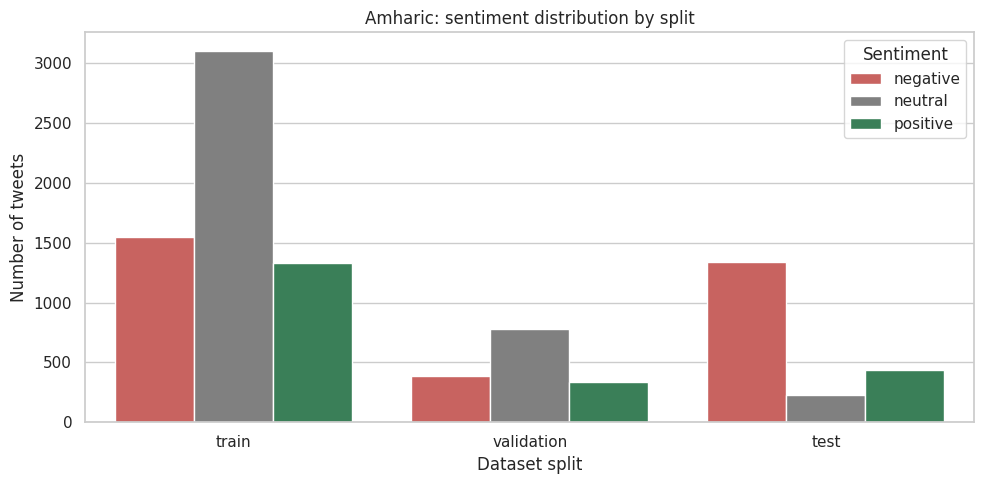

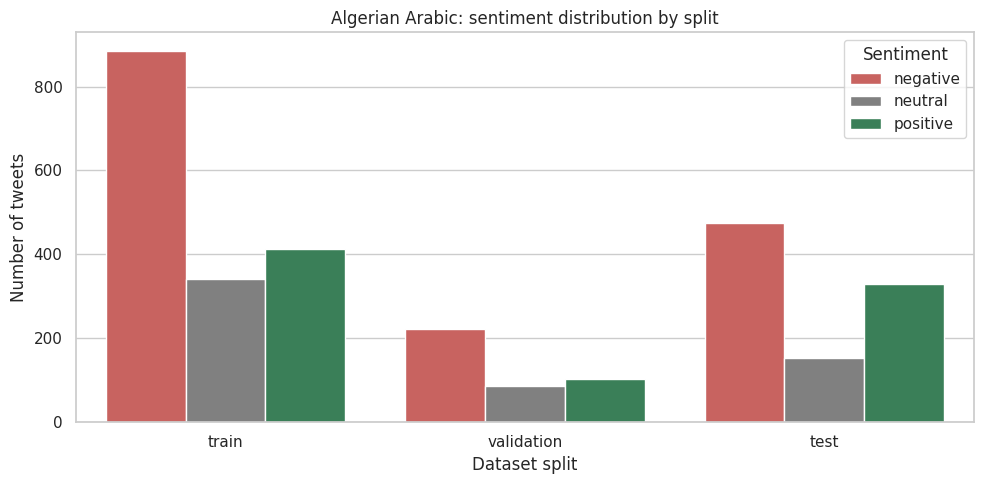

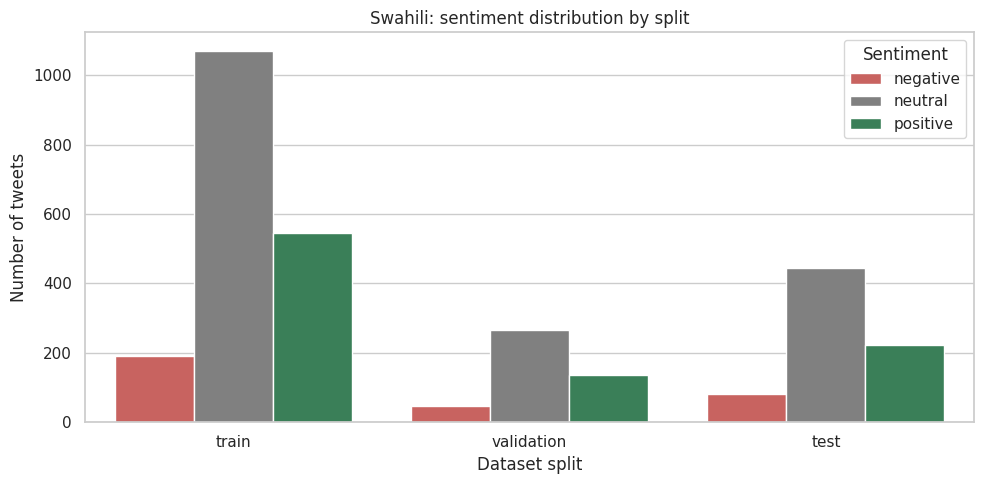

In [21]:
sns.set_theme(style="whitegrid")

for language_name in cleaned_frames:
    language_data = label_distribution[
        label_distribution["language"] == language_name
    ]

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=language_data,
        x="split",
        y="count",
        hue="sentiment",
        hue_order=["negative", "neutral", "positive"],
        palette={
            "negative": "#D9534F",
            "neutral": "#808080",
            "positive": "#2E8B57",
        },
    )

    plt.title(f"{language_name}: sentiment distribution by split")
    plt.xlabel("Dataset split")
    plt.ylabel("Number of tweets")
    plt.legend(title="Sentiment")
    plt.tight_layout()
    plt.show()

In [22]:
eda_summary_rows = []

for language_name, df in eda_frames.items():
    for label_name in ["negative", "neutral", "positive"]:
        subset = df[df["label_name"] == label_name]

        eda_summary_rows.append({
            "language": language_name,
            "sentiment": label_name,
            "number_of_tweets": len(subset),
            "mean_characters": subset["character_count"].mean(),
            "median_characters": subset["character_count"].median(),
            "mean_words": subset["word_count"].mean(),
            "median_words": subset["word_count"].median(),
            "mean_hashtags": subset["hashtag_count"].mean(),
            "mean_mentions": subset["mention_count"].mean(),
            "mean_urls": subset["url_count"].mean(),
        })

eda_summary = pd.DataFrame(eda_summary_rows)

display(
    eda_summary.round(2)
)

,language,sentiment,number_of_tweets,mean_characters,median_characters,mean_words,median_words,mean_hashtags,mean_mentions,mean_urls
0,Amharic,negative,3272,76.96,80.0,15.59,16.0,0.05,0.42,0.0
1,Amharic,neutral,4104,73.36,73.0,14.83,15.0,0.00,0.04,0.0
2,Amharic,positive,2102,69.06,65.0,13.69,13.0,0.03,0.15,0.0
3,Algerian Arabic,negative,1582,71.17,64.0,12.68,11.0,0.01,1.41,0.0
4,Algerian Arabic,neutral,582,56.18,44.0,10.04,8.0,0.01,1.37,0.0
5,Algerian Arabic,positive,846,62.98,54.0,11.13,9.0,0.03,1.26,0.0
6,Swahili,negative,319,119.50,115.0,18.64,18.0,0.00,0.00,0.0
7,Swahili,neutral,1780,104.94,104.0,16.47,16.0,0.00,0.00,0.0
8,Swahili,positive,903,110.27,107.0,17.26,16.0,0.00,0.00,0.0


In [23]:
def dataframe_to_hf_dataset(df):
    required_columns = ["text", "label"]

    hf_df = df[required_columns].copy()
    hf_df["label"] = hf_df["label"].astype(int)

    return Dataset.from_pandas(
        hf_df,
        preserve_index=False,
    )


hf_datasets = {}

for language_name, split_frames in cleaned_frames.items():
    if "train" not in split_frames:
        raise ValueError(
            f"{language_name} has no training split."
        )

    if "validation" not in split_frames:
        raise ValueError(
            f"{language_name} has no validation split."
        )

    if "test" not in split_frames:
        raise ValueError(
            f"{language_name} has no test split."
        )

    hf_datasets[language_name] = DatasetDict({
        "train": dataframe_to_hf_dataset(
            split_frames["train"]
        ),
        "validation": dataframe_to_hf_dataset(
            split_frames["validation"]
        ),
        "test": dataframe_to_hf_dataset(
            split_frames["test"]
        ),
    })

    print(language_name)
    print(hf_datasets[language_name])

Amharic
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 5982
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1497
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1999
    })
})
Algerian Arabic
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1641
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 411
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 958
    })
})
Swahili
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1805
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 450
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 747
    })
})


In [24]:
def compute_metrics(eval_prediction):
    logits, true_labels = eval_prediction

    predicted_labels = np.argmax(
        logits,
        axis=-1,
    )

    accuracy = accuracy_score(
        true_labels,
        predicted_labels,
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0,
        )
    )

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            average="weighted",
            zero_division=0,
        )
    )

    class_precision, class_recall, class_f1, class_support = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            labels=[0, 1, 2],
            average=None,
            zero_division=0,
        )
    )

    return {
        "accuracy": accuracy,

        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,

        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall,
        "weighted_f1": weighted_f1,

        "negative_f1": class_f1[0],
        "neutral_f1": class_f1[1],
        "positive_f1": class_f1[2],
    }

In [25]:
def create_training_arguments(output_dir, run_name):
    # Check which arguments are supported by the installed version of Transformers.
    supported_args = inspect.signature(
        TrainingArguments.__init__
    ).parameters

    arguments = {
        "output_dir": output_dir,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "per_device_train_batch_size": TRAIN_BATCH_SIZE,
        "per_device_eval_batch_size": EVAL_BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
        "num_train_epochs": NUM_EPOCHS,
        "warmup_ratio": WARMUP_RATIO,
        "lr_scheduler_type": LR_SCHEDULER_TYPE,
        "max_grad_norm": MAX_GRAD_NORM,
        "save_strategy": "epoch",
        "save_total_limit": 1,
        "logging_strategy": "steps",
        "logging_steps": 50,
        "load_best_model_at_end": True,
        "metric_for_best_model": "macro_f1",
        "greater_is_better": True,
        "seed": SEED,
        "data_seed": SEED,
        "report_to": "none",
        "run_name": run_name,
    }

    # Evaluation-strategy compatibility
    if "eval_strategy" in supported_args:
        arguments["eval_strategy"] = "epoch"
    elif "evaluation_strategy" in supported_args:
        arguments["evaluation_strategy"] = "epoch"

    # Mixed precision
    if "fp16" in supported_args:
        arguments["fp16"] = bool(torch.cuda.is_available())

    # Dataloader workers
    if "dataloader_num_workers" in supported_args:
        arguments["dataloader_num_workers"] = 2

    # Filter to only allow valid parameters to prevent unexpected keyword argument errors
    filtered_arguments = {
        key: value
        for key, value in arguments.items()
        if key in supported_args
    }

    print("\nTrainingArguments being used:")
    for key, value in filtered_arguments.items():
        print(f"  {key}: {value}")

    return TrainingArguments(**filtered_arguments)

In [26]:
import inspect

print("Supported TrainingArguments parameters:\n")

params = inspect.signature(
    TrainingArguments.__init__
).parameters

print(list(params.keys()))

Supported TrainingArguments parameters:

['self', 'output_dir', 'per_device_train_batch_size', 'num_train_epochs', 'max_steps', 'learning_rate', 'lr_scheduler_type', 'lr_scheduler_kwargs', 'warmup_steps', 'optim', 'optim_args', 'weight_decay', 'adam_beta1', 'adam_beta2', 'adam_epsilon', 'optim_target_modules', 'gradient_accumulation_steps', 'average_tokens_across_devices', 'max_grad_norm', 'label_smoothing_factor', 'bf16', 'fp16', 'bf16_full_eval', 'fp16_full_eval', 'tf32', 'gradient_checkpointing', 'gradient_checkpointing_kwargs', 'torch_compile', 'torch_compile_backend', 'torch_compile_mode', 'use_liger_kernel', 'liger_kernel_config', 'use_cache', 'neftune_noise_alpha', 'torch_empty_cache_steps', 'auto_find_batch_size', 'logging_strategy', 'logging_steps', 'logging_first_step', 'log_on_each_node', 'logging_nan_inf_filter', 'include_num_input_tokens_seen', 'log_level', 'log_level_replica', 'disable_tqdm', 'report_to', 'run_name', 'project', 'trackio_space_id', 'trackio_bucket_id', 'tr

In [27]:
test_args = create_training_arguments(
    output_dir="/content/test_training_args",
    run_name="test_run"
)

print("\nSUCCESS!")
print(test_args)


TrainingArguments being used:
  output_dir: /content/test_training_args
  learning_rate: 2e-05
  weight_decay: 0.01
  per_device_train_batch_size: 16
  per_device_eval_batch_size: 32
  gradient_accumulation_steps: 2
  num_train_epochs: 5
  lr_scheduler_type: linear
  max_grad_norm: 1.0
  save_strategy: epoch
  save_total_limit: 1
  logging_strategy: steps
  logging_steps: 50
  load_best_model_at_end: True
  metric_for_best_model: macro_f1
  greater_is_better: True
  seed: 42
  data_seed: 42
  report_to: none
  run_name: test_run
  eval_strategy: epoch
  fp16: True
  dataloader_num_workers: 2

SUCCESS!
TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,


In [28]:
def train_and_evaluate_model(
    language_name,
    model_name,
    model_checkpoint,
    dataset_dict,
):
    safe_language = (
        language_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    safe_model = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    experiment_name = f"{safe_language}_{safe_model}"

    experiment_dir = os.path.join(
        OUTPUT_ROOT,
        "models",
        experiment_name,
    )

    os.makedirs(experiment_dir, exist_ok=True)

    print("\n" + "=" * 100)
    print("Language:", language_name)
    print("Model:", model_name)
    print("Checkpoint:", model_checkpoint)
    print("Output:", experiment_dir)
    print("=" * 100)

    # ----------------------------------------------------------
    # 1. Tokenizer
    # ----------------------------------------------------------
    tokenizer = AutoTokenizer.from_pretrained(
        model_checkpoint,
        use_fast=False,
    )

    # AfriBERTa's model card recommends manually defining this.
    tokenizer.model_max_length = MAX_LENGTH

    # ----------------------------------------------------------
    # 2. Tokenization
    # ----------------------------------------------------------
    def tokenize_batch(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

    tokenized_dataset = dataset_dict.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"],
        desc=f"Tokenizing {language_name} with {model_name}",
    )

    tokenized_dataset = tokenized_dataset.rename_column(
        "label",
        "labels",
    )

    tokenized_dataset.set_format("torch")

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        pad_to_multiple_of=8 if torch.cuda.is_available() else None,
    )

    # ----------------------------------------------------------
    # 3. Model configuration
    # ----------------------------------------------------------
    model_config = AutoConfig.from_pretrained(
        model_checkpoint,
        num_labels=NUM_LABELS,
        label2id=LABEL2ID,
        id2label=ID2LABEL,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_checkpoint,
        config=model_config,
        ignore_mismatched_sizes=True,
    )

    # ----------------------------------------------------------
    # 4. Training arguments
    # ----------------------------------------------------------
    training_args = create_training_arguments(
        output_dir=experiment_dir,
        run_name=experiment_name,
    )

    # ----------------------------------------------------------
    # 5. Trainer
    # ----------------------------------------------------------
    trainer_parameters = inspect.signature(
        Trainer.__init__
    ).parameters

    trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": tokenized_dataset["train"],
        "eval_dataset": tokenized_dataset["validation"],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [
            EarlyStoppingCallback(
                early_stopping_patience=EARLY_STOPPING_PATIENCE
            )
        ],
    }

    # Different Transformers versions use different parameter names.
    if "processing_class" in trainer_parameters:
        trainer_kwargs["processing_class"] = tokenizer

    elif "tokenizer" in trainer_parameters:
        trainer_kwargs["tokenizer"] = tokenizer

    trainer = Trainer(**trainer_kwargs)

    # ----------------------------------------------------------
    # 6. Train
    # ----------------------------------------------------------
    train_result = trainer.train()

    # ----------------------------------------------------------
    # 7. Validation evaluation
    # ----------------------------------------------------------
    validation_metrics = trainer.evaluate(
        eval_dataset=tokenized_dataset["validation"],
        metric_key_prefix="validation",
    )

    # ----------------------------------------------------------
    # 8. Test predictions
    # ----------------------------------------------------------
    test_predictions = trainer.predict(
        tokenized_dataset["test"],
        metric_key_prefix="test",
    )

    test_logits = test_predictions.predictions
    test_true = test_predictions.label_ids

    test_predicted = np.argmax(
        test_logits,
        axis=-1,
    )

    test_probabilities = torch.softmax(
        torch.tensor(test_logits),
        dim=-1,
    ).numpy()

    # ----------------------------------------------------------
    # 9. Detailed classification report
    # ----------------------------------------------------------
    report_dict = classification_report(
        test_true,
        test_predicted,
        labels=[0, 1, 2],
        target_names=[
            "negative",
            "neutral",
            "positive",
        ],
        output_dict=True,
        zero_division=0,
    )

    report_df = (
        pd.DataFrame(report_dict)
        .transpose()
        .reset_index()
        .rename(columns={"index": "class"})
    )

    report_df.to_csv(
        os.path.join(
            experiment_dir,
            "classification_report.csv",
        ),
        index=False,
    )

    # ----------------------------------------------------------
    # 10. Save predictions
    # ----------------------------------------------------------
    predictions_df = pd.DataFrame({
        "text": cleaned_frames[language_name]["test"]["text"].values,
        "true_label_id": test_true,
        "predicted_label_id": test_predicted,
        "true_label": [
            ID2LABEL[int(value)]
            for value in test_true
        ],
        "predicted_label": [
            ID2LABEL[int(value)]
            for value in test_predicted
        ],
        "probability_negative": test_probabilities[:, 0],
        "probability_neutral": test_probabilities[:, 1],
        "probability_positive": test_probabilities[:, 2],
    })

    predictions_df["correct"] = (
        predictions_df["true_label_id"]
        == predictions_df["predicted_label_id"]
    )

    predictions_df.to_csv(
        os.path.join(
            experiment_dir,
            "test_predictions.csv",
        ),
        index=False,
        encoding="utf-8-sig",
    )

    # ----------------------------------------------------------
    # 11. Confusion matrix
    # ----------------------------------------------------------
    matrix = confusion_matrix(
        test_true,
        test_predicted,
        labels=[0, 1, 2],
    )

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "negative",
            "neutral",
            "positive",
        ],
        yticklabels=[
            "negative",
            "neutral",
            "positive",
        ],
    )

    plt.title(
        f"{language_name} – {model_name}\n"
        f"Test confusion matrix"
    )
    plt.xlabel("Predicted sentiment")
    plt.ylabel("True sentiment")
    plt.tight_layout()

    confusion_matrix_path = os.path.join(
        experiment_dir,
        "confusion_matrix.png",
    )

    plt.savefig(
        confusion_matrix_path,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()

    # ----------------------------------------------------------
    # 12. Save model and tokenizer
    # ----------------------------------------------------------
    best_model_dir = os.path.join(
        experiment_dir,
        "best_model",
    )

    trainer.save_model(best_model_dir)
    tokenizer.save_pretrained(best_model_dir)

    # ----------------------------------------------------------
    # 13. Save parameter configuration
    # ----------------------------------------------------------
    parameter_record = {
        "language": language_name,
        "model_name": model_name,
        "model_checkpoint": model_checkpoint,
        "maximum_length": MAX_LENGTH,
        "training_batch_size": TRAIN_BATCH_SIZE,
        "evaluation_batch_size": EVAL_BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
        "effective_training_batch_size": (
            TRAIN_BATCH_SIZE
            * GRADIENT_ACCUMULATION_STEPS
        ),
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "maximum_epochs": NUM_EPOCHS,
        "warmup_ratio": WARMUP_RATIO,
        "learning_rate_scheduler": LR_SCHEDULER_TYPE,
        "maximum_gradient_norm": MAX_GRAD_NORM,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "selection_metric": "macro_f1",
        "optimizer": "AdamW",
        "seed": SEED,
        "fp16": bool(torch.cuda.is_available()),
        "train_size": len(dataset_dict["train"]),
        "validation_size": len(dataset_dict["validation"]),
        "test_size": len(dataset_dict["test"]),
    }

    with open(
        os.path.join(
            experiment_dir,
            "training_parameters.json",
        ),
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            parameter_record,
            file,
            indent=4,
            ensure_ascii=False,
        )

    # ----------------------------------------------------------
    # 14. Prepare single-row result
    # ----------------------------------------------------------
    test_metrics = test_predictions.metrics

    result = {
        "language": language_name,
        "model": model_name,
        "model_checkpoint": model_checkpoint,

        "train_size": len(dataset_dict["train"]),
        "validation_size": len(dataset_dict["validation"]),
        "test_size": len(dataset_dict["test"]),

        "accuracy": test_metrics.get("test_accuracy"),
        "macro_precision": test_metrics.get("test_macro_precision"),
        "macro_recall": test_metrics.get("test_macro_recall"),
        "macro_f1": test_metrics.get("test_macro_f1"),

        "weighted_precision": test_metrics.get(
            "test_weighted_precision"
        ),
        "weighted_recall": test_metrics.get(
            "test_weighted_recall"
        ),
        "weighted_f1": test_metrics.get(
            "test_weighted_f1"
        ),

        "negative_f1": test_metrics.get("test_negative_f1"),
        "neutral_f1": test_metrics.get("test_neutral_f1"),
        "positive_f1": test_metrics.get("test_positive_f1"),

        "test_loss": test_metrics.get("test_loss"),
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "output_directory": experiment_dir,
    }

    with open(
        os.path.join(
            experiment_dir,
            "test_metrics.json",
        ),
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            result,
            file,
            indent=4,
            ensure_ascii=False,
        )

    print("\nTest results:")
    display(pd.DataFrame([result]).round(4))

    # ----------------------------------------------------------
    # 15. Release GPU memory
    # ----------------------------------------------------------
    del trainer
    del model
    del tokenizer
    del tokenized_dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


Language: Amharic
Model: XLM-R
Checkpoint: FacebookAI/xlm-roberta-base
Output: /content/afrisenti_monolingual_results/models/amharic_xlm_r


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Tokenizing Amharic with XLM-R:   0%|          | 0/5982 [00:00<?, ? examples/s]

... (11 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.374900,0.873611,5,0.593854,0.577219,0.583492,0.580069,0.593973,0.593854,0.593700,0.494792,0.636719,0.608696


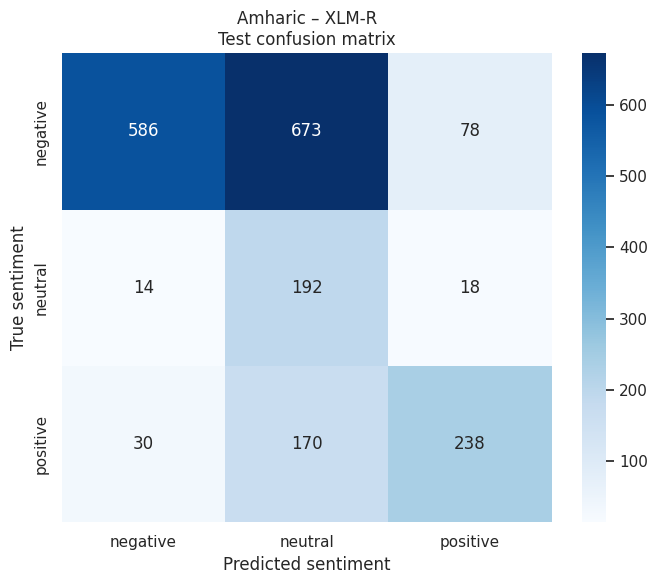

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Amharic,XLM-R,FacebookAI/xlm-roberta-base,5982,1497,1999,0.5083,0.6094,0.6129,0.5058,0.799,0.5083,0.5678,0.5958,0.305,0.6166,1.1352,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Amharic
Model: AfroXLM-R
Checkpoint: Davlan/afro-xlmr-base
Output: /content/afrisenti_monolingual_results/models/amharic_afroxlm_r


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

... (16 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.215937,0.840279,5,0.628591,0.627411,0.589962,0.604243,0.627581,0.628591,0.623972,0.503477,0.683423,0.625828


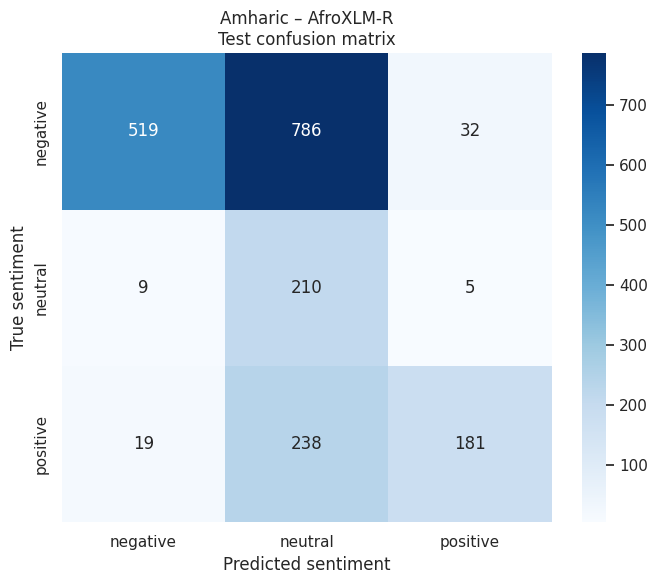

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Amharic,AfroXLM-R,Davlan/afro-xlmr-base,5982,1497,1999,0.4552,0.6498,0.5796,0.4636,0.8356,0.4552,0.5217,0.551,0.2881,0.5518,1.2018,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Amharic
Model: AfriBERTa
Checkpoint: castorini/afriberta_base
Output: /content/afrisenti_monolingual_results/models/amharic_afriberta


config.json:   0%|          | 0.00/729 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
0.878330,1.011230,5,0.603206,0.590756,0.582786,0.586519,0.602467,0.603206,0.602615,0.481144,0.653992,0.624420


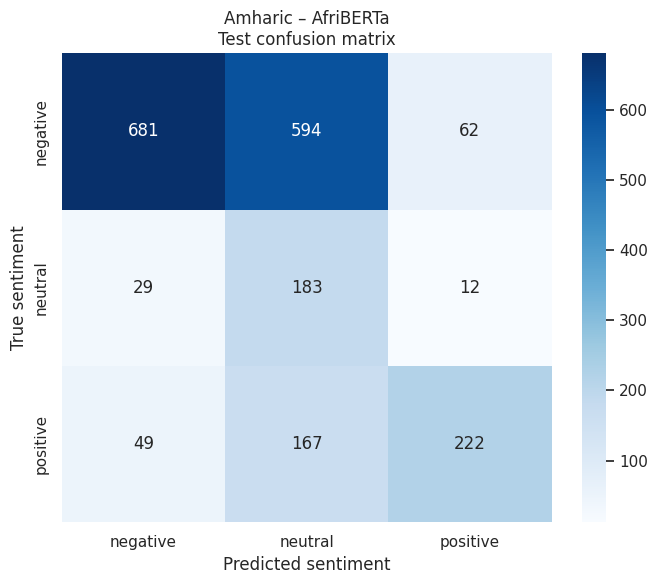

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Amharic,AfriBERTa,castorini/afriberta_base,5982,1497,1999,0.5433,0.6137,0.6111,0.5227,0.7862,0.5433,0.6023,0.6498,0.3134,0.6049,1.1982,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Algerian Arabic
Model: XLM-R
Checkpoint: FacebookAI/xlm-roberta-base
Output: /content/afrisenti_monolingual_results/models/algerian_arabic_xlm_r


Tokenizing Algerian Arabic with XLM-R:   0%|          | 0/1641 [00:00<?, ? examples/s]

Tokenizing Algerian Arabic with XLM-R:   0%|          | 0/411 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.765718,0.876791,5,0.620438,0.597946,0.501952,0.512649,0.609011,0.620438,0.584179,0.729679,0.302521,0.505747


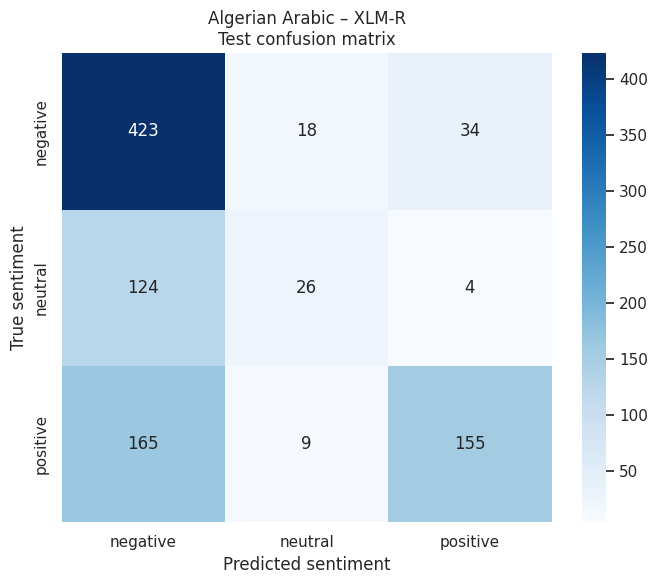

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Algerian Arabic,XLM-R,FacebookAI/xlm-roberta-base,1641,411,958,0.6305,0.6293,0.5102,0.5193,0.6492,0.6305,0.5977,0.7127,0.2512,0.5939,0.8814,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Algerian Arabic
Model: AfroXLM-R
Checkpoint: Davlan/afro-xlmr-base
Output: /content/afrisenti_monolingual_results/models/algerian_arabic_afroxlm_r


Tokenizing Algerian Arabic with AfroXLM-R:   0%|          | 0/1641 [00:00<?, ? examples/s]

Tokenizing Algerian Arabic with AfroXLM-R:   0%|          | 0/411 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.269745,0.852034,5,0.635036,0.620549,0.543650,0.556328,0.629038,0.635036,0.612444,0.723658,0.370968,0.574359


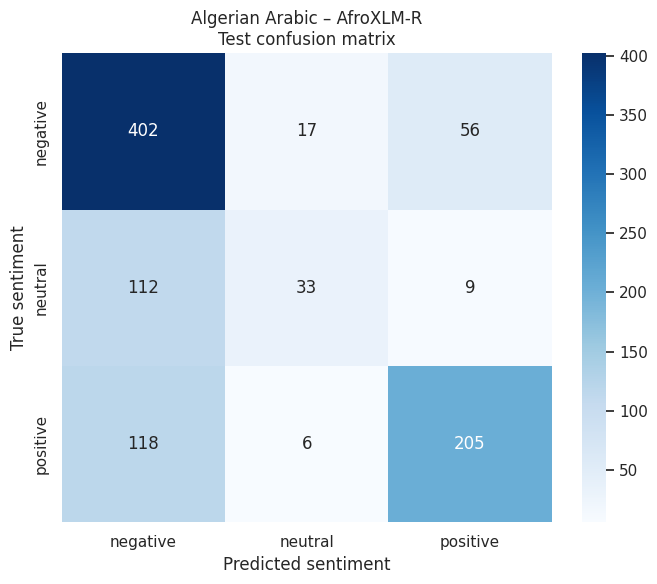

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Algerian Arabic,AfroXLM-R,Davlan/afro-xlmr-base,1641,411,958,0.6681,0.6615,0.5612,0.575,0.6709,0.6681,0.6457,0.7263,0.3143,0.6845,0.7966,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Algerian Arabic
Model: AfriBERTa
Checkpoint: castorini/afriberta_base
Output: /content/afrisenti_monolingual_results/models/algerian_arabic_afriberta


Tokenizing Algerian Arabic with AfriBERTa:   0%|          | 0/1641 [00:00<?, ? examples/s]

Tokenizing Algerian Arabic with AfriBERTa:   0%|          | 0/411 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.894858,0.980531,4,0.537713,0.511867,0.407446,0.381905,0.539539,0.537713,0.473354,0.688766,0.319018,0.137931


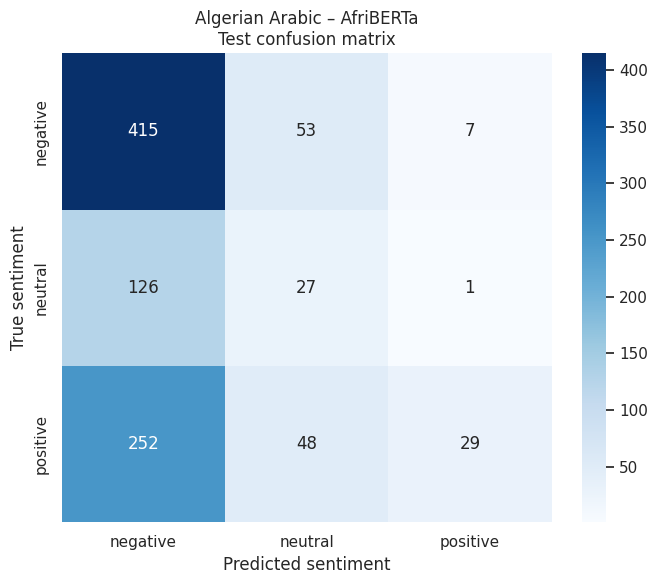

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Algerian Arabic,AfriBERTa,castorini/afriberta_base,1641,411,958,0.4916,0.506,0.3791,0.3348,0.5626,0.4916,0.4098,0.6546,0.1915,0.1585,1.0416,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Swahili
Model: XLM-R
Checkpoint: FacebookAI/xlm-roberta-base
Output: /content/afrisenti_monolingual_results/models/swahili_xlm_r


Tokenizing Swahili with XLM-R:   0%|          | 0/1805 [00:00<?, ? examples/s]

Tokenizing Swahili with XLM-R:   0%|          | 0/450 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.570330,0.849167,5,0.613333,0.389599,0.416538,0.398116,0.538707,0.613333,0.568538,0.000000,0.718543,0.475806


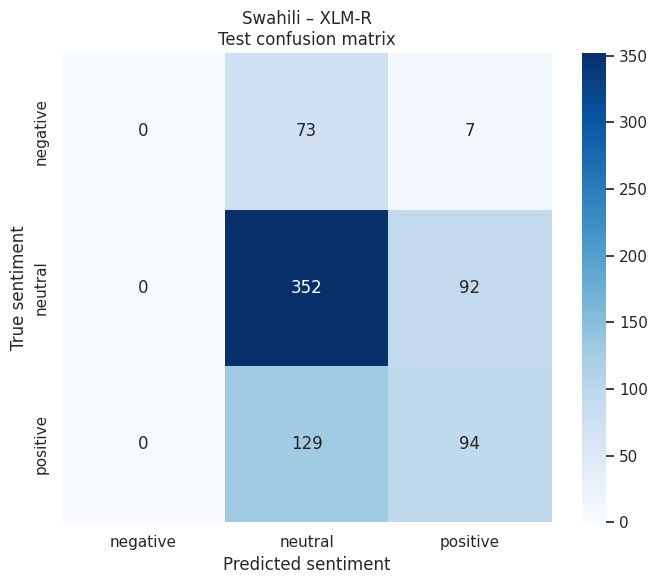

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Swahili,XLM-R,FacebookAI/xlm-roberta-base,1805,450,747,0.5971,0.3741,0.4048,0.3858,0.5231,0.5971,0.5542,0.0,0.7054,0.4519,0.8451,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Swahili
Model: AfroXLM-R
Checkpoint: Davlan/afro-xlmr-base
Output: /content/afrisenti_monolingual_results/models/swahili_afroxlm_r


Tokenizing Swahili with AfroXLM-R:   0%|          | 0/1805 [00:00<?, ? examples/s]

Tokenizing Swahili with AfroXLM-R:   0%|          | 0/450 [00:00<?, ? examples/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
1.255542,0.823808,5,0.628889,0.568056,0.537038,0.549443,0.618255,0.628889,0.621159,0.436782,0.721429,0.490119


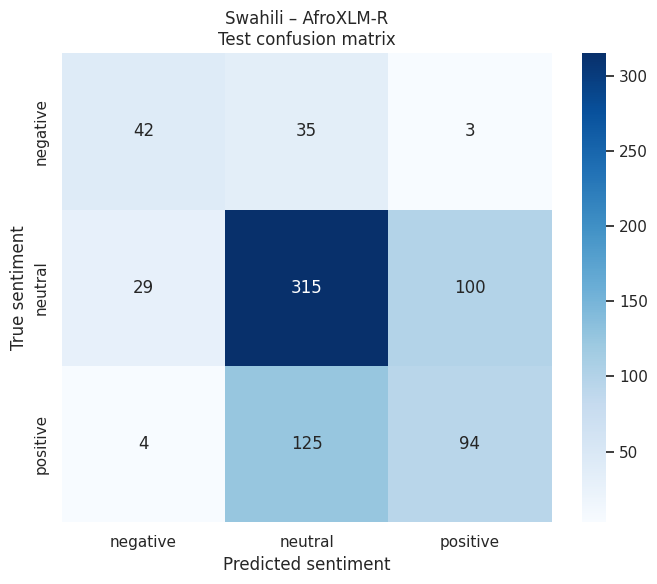

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Swahili,AfroXLM-R,Davlan/afro-xlmr-base,1805,450,747,0.6037,0.5668,0.552,0.5584,0.5966,0.6037,0.5991,0.5419,0.6855,0.4476,0.7987,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...



Language: Swahili
Model: AfriBERTa
Checkpoint: castorini/afriberta_base
Output: /content/afrisenti_monolingual_results/models/swahili_afriberta


Tokenizing Swahili with AfriBERTa:   0%|          | 0/1805 [00:00<?, ? examples/s]

Tokenizing Swahili with AfriBERTa:   0%|          | 0/450 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative F1,Neutral F1,Positive F1
0.985963,0.836670,4,0.608889,0.579844,0.481129,0.504623,0.599115,0.608889,0.593491,0.352941,0.709565,0.451362


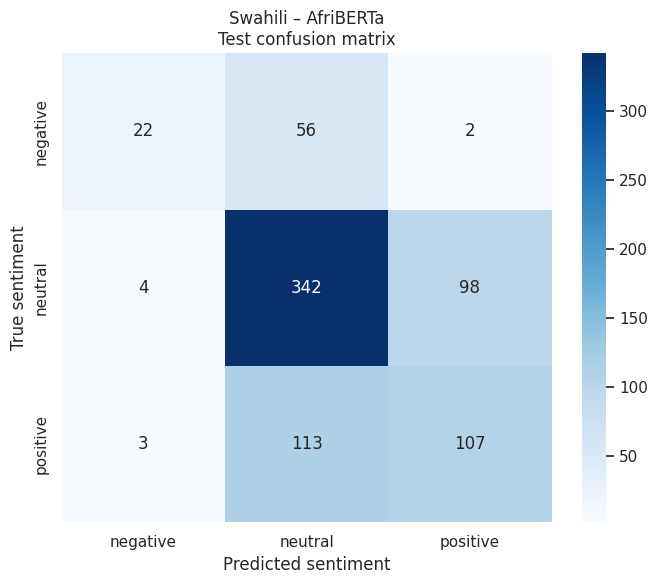

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Test results:


,language,model,model_checkpoint,train_size,validation_size,test_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,negative_f1,neutral_f1,positive_f1,test_loss,best_checkpoint,output_directory
0,Swahili,AfriBERTa,castorini/afriberta_base,1805,450,747,0.6305,0.6483,0.5084,0.5392,0.6334,0.6305,0.6175,0.4037,0.7162,0.4977,0.7734,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...


In [29]:
all_results = []

for language_name, dataset_dict in hf_datasets.items():
    for model_name, model_checkpoint in MODEL_CONFIG.items():

        try:
            result = train_and_evaluate_model(
                language_name=language_name,
                model_name=model_name,
                model_checkpoint=model_checkpoint,
                dataset_dict=dataset_dict,
            )

            all_results.append(result)

        except Exception as error:
            print("\n" + "!" * 100)
            print(
                f"Experiment failed: "
                f"{language_name} | {model_name}"
            )
            print(type(error).__name__, ":", error)
            print("!" * 100)

            all_results.append({
                "language": language_name,
                "model": model_name,
                "model_checkpoint": model_checkpoint,
                "error": str(error),
            })

        results_so_far = pd.DataFrame(all_results)

        results_so_far.to_csv(
            os.path.join(
                OUTPUT_ROOT,
                "results_so_far.csv",
            ),
            index=False,
        )

In [30]:
results_df = pd.DataFrame(all_results)

successful_results = results_df[
    results_df["macro_f1"].notna()
].copy()

successful_results = successful_results.sort_values(
    by=["language", "macro_f1"],
    ascending=[True, False],
).reset_index(drop=True)

display(
    successful_results[
        [
            "language",
            "model",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "negative_f1",
            "neutral_f1",
            "positive_f1",
        ]
    ].round(4)
)

,language,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Algerian Arabic,AfroXLM-R,0.6681,0.6615,0.5612,0.5750,0.6457,0.7263,0.3143,0.6845
1,Algerian Arabic,XLM-R,0.6305,0.6293,0.5102,0.5193,0.5977,0.7127,0.2512,0.5939
2,Algerian Arabic,AfriBERTa,0.4916,0.5060,0.3791,0.3348,0.4098,0.6546,0.1915,0.1585
3,Amharic,AfriBERTa,0.5433,0.6137,0.6111,0.5227,0.6023,0.6498,0.3134,0.6049
4,Amharic,XLM-R,0.5083,0.6094,0.6129,0.5058,0.5678,0.5958,0.3050,0.6166
5,Amharic,AfroXLM-R,0.4552,0.6498,0.5796,0.4636,0.5217,0.5510,0.2881,0.5518
6,Swahili,AfroXLM-R,0.6037,0.5668,0.5520,0.5584,0.5991,0.5419,0.6855,0.4476
7,Swahili,AfriBERTa,0.6305,0.6483,0.5084,0.5392,0.6175,0.4037,0.7162,0.4977
8,Swahili,XLM-R,0.5971,0.3741,0.4048,0.3858,0.5542,0.0000,0.7054,0.4519


In [31]:
best_models = (
    successful_results
    .sort_values(
        ["language", "macro_f1"],
        ascending=[True, False],
    )
    .groupby("language", as_index=False)
    .first()
)

display(
    best_models[
        [
            "language",
            "model",
            "accuracy",
            "macro_f1",
            "weighted_f1",
            "negative_f1",
            "neutral_f1",
            "positive_f1",
        ]
    ].round(4)
)

,language,model,accuracy,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Algerian Arabic,AfroXLM-R,0.6681,0.5750,0.6457,0.7263,0.3143,0.6845
1,Amharic,AfriBERTa,0.5433,0.5227,0.6023,0.6498,0.3134,0.6049
2,Swahili,AfroXLM-R,0.6037,0.5584,0.5991,0.5419,0.6855,0.4476


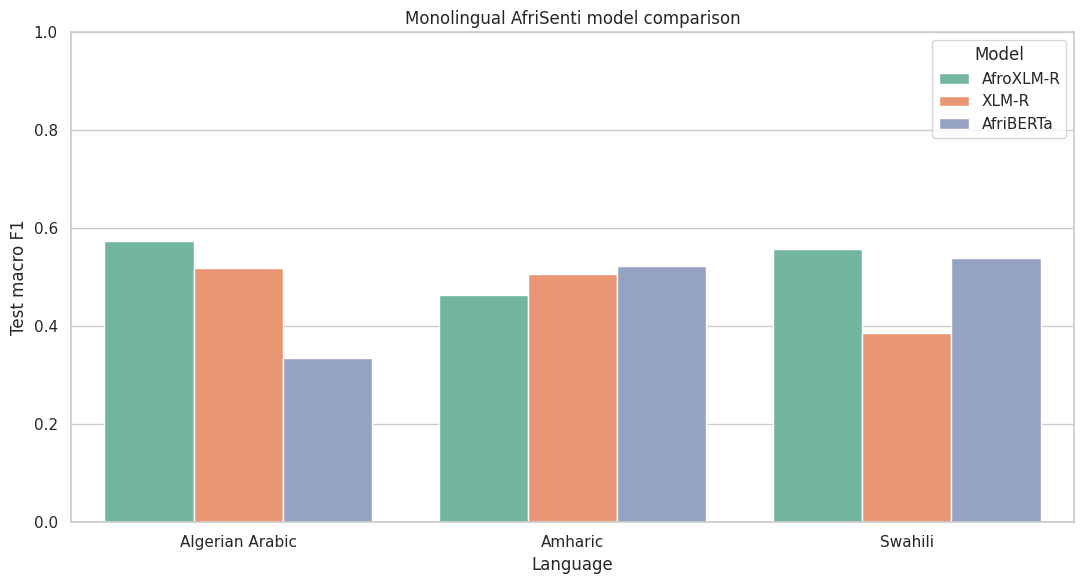

In [32]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=successful_results,
    x="language",
    y="macro_f1",
    hue="model",
    palette="Set2",
)

plt.title("Monolingual AfriSenti model comparison")
plt.xlabel("Language")
plt.ylabel("Test macro F1")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

comparison_plot_path = os.path.join(
    OUTPUT_ROOT,
    "macro_f1_comparison.png",
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [33]:
macro_f1_table = successful_results.pivot(
    index="language",
    columns="model",
    values="macro_f1",
)

accuracy_table = successful_results.pivot(
    index="language",
    columns="model",
    values="accuracy",
)

print("Macro F1")
display(macro_f1_table.round(4))

print("Accuracy")
display(accuracy_table.round(4))

Macro F1


model,AfriBERTa,AfroXLM-R,XLM-R
language,,,
Algerian Arabic,0.3348,0.5750,0.5193
Amharic,0.5227,0.4636,0.5058
Swahili,0.5392,0.5584,0.3858


Accuracy


model,AfriBERTa,AfroXLM-R,XLM-R
language,,,
Algerian Arabic,0.4916,0.6681,0.6305
Amharic,0.5433,0.4552,0.5083
Swahili,0.6305,0.6037,0.5971


In [34]:
FINAL_RESULTS_PATH = os.path.join(
    OUTPUT_ROOT,
    "afrisenti_model_comparison.xlsx",
)

with pd.ExcelWriter(
    FINAL_RESULTS_PATH,
    engine="openpyxl",
) as writer:

    successful_results.to_excel(
        writer,
        sheet_name="All results",
        index=False,
    )

    best_models.to_excel(
        writer,
        sheet_name="Best models",
        index=False,
    )

    macro_f1_table.to_excel(
        writer,
        sheet_name="Macro F1",
    )

    accuracy_table.to_excel(
        writer,
        sheet_name="Accuracy",
    )

    dataset_size_summary.to_excel(
        writer,
        sheet_name="Dataset sizes",
        index=False,
    )

    label_distribution.to_excel(
        writer,
        sheet_name="Label distribution",
        index=False,
    )

    eda_summary.to_excel(
        writer,
        sheet_name="Text statistics",
        index=False,
    )

print("Saved:", FINAL_RESULTS_PATH)

Saved: /content/afrisenti_monolingual_results/afrisenti_model_comparison.xlsx


In [37]:
CS_LANGUAGE_CONFIG = {
    "Igbo": "ibo",
    "Nigerian Pidgin": "pcm",
    "Twi": "twi",
}

# Existing monolingual languages from the previous experiment
MONO_LANGUAGE_NAMES = [
    "Amharic",
    "Algerian Arabic",
    "Swahili",
]

# Same model checkpoints used previously
MODEL_CONFIG = {
    "XLM-R": "FacebookAI/xlm-roberta-base",
    "AfroXLM-R": "Davlan/afro-xlmr-base",
    "AfriBERTa": "castorini/afriberta_base",
}

CS_OUTPUT_ROOT = os.path.join(
    OUTPUT_ROOT,
    "code_switched_experiments",
)

os.makedirs(CS_OUTPUT_ROOT, exist_ok=True)

print("CS output directory:", CS_OUTPUT_ROOT)

CS output directory: /content/afrisenti_monolingual_results/code_switched_experiments


In [38]:
cs_raw_datasets = {}

for language_name, config_name in CS_LANGUAGE_CONFIG.items():
    print("=" * 80)
    print(f"Loading {language_name} ({config_name})")

    dataset = load_dataset(
        DATASET_NAME,
        config_name,
    )

    cs_raw_datasets[language_name] = dataset

    print(dataset)

    for split_name, split_dataset in dataset.items():
        print(
            f"{language_name:20s} | "
            f"{split_name:12s} | "
            f"{len(split_dataset):,} rows | "
            f"columns: {split_dataset.column_names}"
        )

Loading Igbo (ibo)
DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 10192
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1841
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 3682
    })
})
Igbo                 | train        | 10,192 rows | columns: ['tweet', 'label']
Igbo                 | validation   | 1,841 rows | columns: ['tweet', 'label']
Igbo                 | test         | 3,682 rows | columns: ['tweet', 'label']
Loading Nigerian Pidgin (pcm)
DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 5121
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 1281
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 4154
    })
})
Nigerian Pidgin      | train        | 5,121 rows | columns: ['tweet', 'label']
Nigerian Pidgin      | validation   | 1,281 rows | column

In [39]:
cs_cleaned_frames = {}

for language_name, dataset_dict in cs_raw_datasets.items():
    cs_cleaned_frames[language_name] = {}

    print("\n" + "=" * 80)
    print(language_name)

    for split_name, split_dataset in dataset_dict.items():
        cleaned_df = clean_dataset_split(
            hf_split=split_dataset,
            language_name=language_name,
            split_name=split_name,
        )

        cleaned_df["dataset_group"] = "CS"

        cs_cleaned_frames[language_name][split_name] = cleaned_df


Igbo
Igbo                 | train        | before=10,192 | after=10,192 | removed=0
Igbo                 | validation   | before=1,841 | after=1,841 | removed=0
Igbo                 | test         | before=3,682 | after=3,682 | removed=0

Nigerian Pidgin
Nigerian Pidgin      | train        | before=5,121 | after=4,641 | removed=480
Nigerian Pidgin      | validation   | before=1,281 | after=1,249 | removed=32
Nigerian Pidgin      | test         | before=4,154 | after=4,154 | removed=0

Twi
Twi                  | train        | before=3,481 | after=3,192 | removed=289
Twi                  | validation   | before=388 | after=386 | removed=2
Twi                  | test         | before=949 | after=949 | removed=0


In [40]:
for language_name in cs_cleaned_frames:
    language_splits = cs_cleaned_frames[language_name]

    if (
        "validation" not in language_splits
        and "dev" in language_splits
    ):
        language_splits["validation"] = (
            language_splits.pop("dev")
        )

        language_splits["validation"]["split"] = "validation"

In [41]:
for language_name in cs_cleaned_frames:
    print("\n" + "=" * 80)
    print(language_name)

    cs_cleaned_frames[language_name] = (
        remove_cross_split_overlap(
            cs_cleaned_frames[language_name]
        )
    )


Igbo
train       : kept=10,192; cross-split duplicates removed=0
validation  : kept=1,803; cross-split duplicates removed=38
test        : kept=3,682; cross-split duplicates removed=0

Nigerian Pidgin
train       : kept=4,641; cross-split duplicates removed=0
validation  : kept=996; cross-split duplicates removed=253
test        : kept=3,026; cross-split duplicates removed=1,128

Twi
train       : kept=3,192; cross-split duplicates removed=0
validation  : kept=312; cross-split duplicates removed=74
test        : kept=730; cross-split duplicates removed=219


In [42]:
cs_size_summary = []

for language_name, split_frames in cs_cleaned_frames.items():
    for split_name, df in split_frames.items():
        cs_size_summary.append({
            "language": language_name,
            "split": split_name,
            "number_of_tweets": len(df),
        })

cs_size_summary = pd.DataFrame(cs_size_summary)

display(
    cs_size_summary.sort_values(
        ["language", "split"]
    ).reset_index(drop=True)
)

,language,split,number_of_tweets
0,Igbo,test,3682
1,Igbo,train,10192
2,Igbo,validation,1803
3,Nigerian Pidgin,test,3026
4,Nigerian Pidgin,train,4641
5,Nigerian Pidgin,validation,996
6,Twi,test,730
7,Twi,train,3192
8,Twi,validation,312


Igbo + Nigerian Pidgin + Twi

In [43]:
def combine_language_frames(
    language_frames,
    split_name,
    dataset_group,
):
    frames = []

    for language_name, split_frames in language_frames.items():
        if split_name not in split_frames:
            raise ValueError(
                f"{split_name!r} is missing for {language_name}."
            )

        frame = split_frames[split_name].copy()
        frame["language"] = language_name
        frame["dataset_group"] = dataset_group

        frames.append(frame)

    combined = pd.concat(
        frames,
        ignore_index=True,
    )

    combined = combined.sample(
        frac=1,
        random_state=SEED,
    ).reset_index(drop=True)

    return combined


cs_pooled_frames = {
    split_name: combine_language_frames(
        language_frames=cs_cleaned_frames,
        split_name=split_name,
        dataset_group="CS",
    )
    for split_name in ["train", "validation", "test"]
}

for split_name, dataframe in cs_pooled_frames.items():
    print(
        f"{split_name:12s}: "
        f"{len(dataframe):,} observations"
    )

train       : 18,025 observations
validation  : 3,111 observations
test        : 7,438 observations


In [44]:
for split_name, dataframe in cs_pooled_frames.items():
    print("\n" + "=" * 80)
    print(split_name.upper())

    language_counts = pd.crosstab(
        dataframe["language"],
        dataframe["label_name"],
        margins=True,
    )

    display(language_counts)


TRAIN


label_name,negative,neutral,positive,All
language,,,,
Igbo,2600,4508,3084,10192
Nigerian Pidgin,3003,70,1568,4641
Twi,1184,510,1498,3192
All,6787,5088,6150,18025



VALIDATION


label_name,negative,neutral,positive,All
language,,,,
Igbo,456,799,548,1803
Nigerian Pidgin,648,17,331,996
Twi,115,48,149,312
All,1219,864,1028,3111



TEST


label_name,negative,neutral,positive,All
language,,,,
Igbo,943,1621,1118,3682
Nigerian Pidgin,1572,429,1025,3026
Twi,257,120,353,730
All,2772,2170,2496,7438


In [45]:
CS_DATA_DIR = os.path.join(
    CS_OUTPUT_ROOT,
    "cleaned_cs_data",
)

os.makedirs(CS_DATA_DIR, exist_ok=True)

for split_name, dataframe in cs_pooled_frames.items():
    file_path = os.path.join(
        CS_DATA_DIR,
        f"pooled_cs_{split_name}.csv",
    )

    dataframe.to_csv(
        file_path,
        index=False,
        encoding="utf-8-sig",
    )

    print("Saved:", file_path)

Saved: /content/afrisenti_monolingual_results/code_switched_experiments/cleaned_cs_data/pooled_cs_train.csv
Saved: /content/afrisenti_monolingual_results/code_switched_experiments/cleaned_cs_data/pooled_cs_validation.csv
Saved: /content/afrisenti_monolingual_results/code_switched_experiments/cleaned_cs_data/pooled_cs_test.csv


In [46]:
def classification_frame_to_dataset(dataframe):
    model_df = dataframe[
        ["text", "label"]
    ].copy()

    model_df["label"] = model_df["label"].astype(int)

    return Dataset.from_pandas(
        model_df,
        preserve_index=False,
    )


cs_hf_dataset = DatasetDict({
    "train": classification_frame_to_dataset(
        cs_pooled_frames["train"]
    ),
    "validation": classification_frame_to_dataset(
        cs_pooled_frames["validation"]
    ),
    "test": classification_frame_to_dataset(
        cs_pooled_frames["test"]
    ),
})

print(cs_hf_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 18025
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 3111
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7438
    })
})


In [47]:
def pool_language_split(
    cleaned_language_frames,
    language_names,
    split_name,
    dataset_group,
):
    pooled_frames = []

    for language_name in language_names:

        if language_name not in cleaned_language_frames:
            raise KeyError(
                f"{language_name} was not found."
            )

        if split_name not in cleaned_language_frames[language_name]:
            raise KeyError(
                f"{split_name} was not found for {language_name}."
            )

        frame = cleaned_language_frames[
            language_name
        ][split_name].copy()

        frame["language"] = language_name
        frame["dataset_group"] = dataset_group

        pooled_frames.append(frame)

    pooled_df = pd.concat(
        pooled_frames,
        ignore_index=True,
    )

    pooled_df = pooled_df.sample(
        frac=1,
        random_state=SEED,
    ).reset_index(drop=True)

    return pooled_df

In [49]:
CS_LANGUAGE_NAMES = list(CS_LANGUAGE_CONFIG.keys())

cs_validation_df = pool_language_split(
    cleaned_language_frames=cs_cleaned_frames,
    language_names=CS_LANGUAGE_NAMES,
    split_name="validation",
    dataset_group="CS",
)

cs_test_df = pool_language_split(
    cleaned_language_frames=cs_cleaned_frames,
    language_names=CS_LANGUAGE_NAMES,
    split_name="test",
    dataset_group="CS",
)

print("CS validation size:", len(cs_validation_df))
print("CS test size:", len(cs_test_df))

display(
    pd.crosstab(
        cs_validation_df["language"],
        cs_validation_df["label_name"],
        margins=True,
    )
)

display(
    pd.crosstab(
        cs_test_df["language"],
        cs_test_df["label_name"],
        margins=True,
    )
)

CS validation size: 3111
CS test size: 7438


label_name,negative,neutral,positive,All
language,,,,
Igbo,456,799,548,1803
Nigerian Pidgin,648,17,331,996
Twi,115,48,149,312
All,1219,864,1028,3111


label_name,negative,neutral,positive,All
language,,,,
Igbo,943,1621,1118,3682
Nigerian Pidgin,1572,429,1025,3026
Twi,257,120,353,730
All,2772,2170,2496,7438


In [50]:
mono_checkpoint_table = successful_results[
    [
        "language",
        "model",
        "model_checkpoint",
        "output_directory",
    ]
].copy()

mono_checkpoint_table["saved_checkpoint"] = (
    mono_checkpoint_table["output_directory"]
    .apply(
        lambda path: os.path.join(
            path,
            "best_model",
        )
    )
)

mono_checkpoint_table["checkpoint_exists"] = (
    mono_checkpoint_table["saved_checkpoint"]
    .apply(os.path.isdir)
)

display(mono_checkpoint_table)

,language,model,model_checkpoint,output_directory,saved_checkpoint,checkpoint_exists
0,Algerian Arabic,AfroXLM-R,Davlan/afro-xlmr-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
1,Algerian Arabic,XLM-R,FacebookAI/xlm-roberta-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
2,Algerian Arabic,AfriBERTa,castorini/afriberta_base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
3,Amharic,AfriBERTa,castorini/afriberta_base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
4,Amharic,XLM-R,FacebookAI/xlm-roberta-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
5,Amharic,AfroXLM-R,Davlan/afro-xlmr-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
6,Swahili,AfroXLM-R,Davlan/afro-xlmr-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
7,Swahili,AfriBERTa,castorini/afriberta_base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True
8,Swahili,XLM-R,FacebookAI/xlm-roberta-base,/content/afrisenti_monolingual_results/models/...,/content/afrisenti_monolingual_results/models/...,True


In [51]:
def classification_frame_to_dataset(dataframe):
    model_df = dataframe[
        ["text", "label"]
    ].copy()

    model_df["label"] = model_df["label"].astype(int)

    return Dataset.from_pandas(
        model_df,
        preserve_index=False,
    )

In [59]:
def evaluate_mono_checkpoint_on_cs(
    checkpoint_path,
    evaluation_df,
    source_language,
    model_name,
    split_name,
):
    print("\n" + "=" * 100)
    print("Source monolingual language:", source_language)
    print("Model:", model_name)
    print("Target split:", split_name)
    print("Checkpoint:", checkpoint_path)
    print("=" * 100)

    # ======================================================
    # 1. Load tokenizer
    # ======================================================

    tokenizer = AutoTokenizer.from_pretrained(
        checkpoint_path,
        use_fast=False,
    )

    tokenizer.model_max_length = MAX_LENGTH

    # ======================================================
    # 2. Load the previously trained monolingual model
    # ======================================================

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            checkpoint_path
        )
    )

    # ======================================================
    # 3. Convert CS evaluation dataframe
    # ======================================================

    evaluation_dataset = (
        classification_frame_to_dataset(
            evaluation_df
        )
    )

    # ======================================================
    # 4. Tokenize
    # ======================================================

    def tokenize_batch(batch):

        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

    tokenized_evaluation = evaluation_dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"],
        desc=(
            f"Tokenizing {split_name} for "
            f"{source_language} {model_name}"
        ),
    )

    tokenized_evaluation = (
        tokenized_evaluation.rename_column(
            "label",
            "labels",
        )
    )

    tokenized_evaluation.set_format("torch")

    # ======================================================
    # 5. Dynamic padding
    # ======================================================

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        pad_to_multiple_of=(
            8 if torch.cuda.is_available()
            else None
        ),
    )

    # ======================================================
    # 6. Evaluation-only arguments
    # ======================================================

    evaluation_output_dir = os.path.join(
        OUTPUT_ROOT,
        "mono_to_cs_evaluation",
        "temporary",
    )

    os.makedirs(
        evaluation_output_dir,
        exist_ok=True,
    )

    evaluation_args = (
        create_evaluation_arguments(
            output_dir=evaluation_output_dir,
            run_name=(
                f"{source_language}_"
                f"{model_name}_"
                f"{split_name}"
                .lower()
                .replace(" ", "_")
                .replace("-", "_")
            ),
        )
    )

    # ======================================================
    # 7. Create prediction-only Trainer
    # ======================================================

    trainer_parameters = inspect.signature(
        Trainer.__init__
    ).parameters

    trainer_kwargs = {
        "model": model,
        "args": evaluation_args,
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
    }

    if "processing_class" in trainer_parameters:

        trainer_kwargs[
            "processing_class"
        ] = tokenizer

    elif "tokenizer" in trainer_parameters:

        trainer_kwargs[
            "tokenizer"
        ] = tokenizer

    trainer = Trainer(
        **trainer_kwargs
    )

    # ======================================================
    # 8. Predict
    # ======================================================

    prediction_output = trainer.predict(
        tokenized_evaluation,
        metric_key_prefix=split_name,
    )

    true_labels = (
        prediction_output.label_ids
    )

    predicted_labels = np.argmax(
        prediction_output.predictions,
        axis=-1,
    )

    probabilities = torch.softmax(
        torch.tensor(
            prediction_output.predictions
        ),
        dim=-1,
    ).numpy()

    # ======================================================
    # 9. Store tweet-level predictions
    # ======================================================

    predictions_df = evaluation_df[
        [
            "text",
            "language",
            "dataset_group",
            "label",
            "label_name",
        ]
    ].copy().reset_index(drop=True)

    if len(predictions_df) != len(true_labels):
        raise ValueError(
            "Evaluation metadata and model predictions "
            "have different numbers of rows."
        )

    predictions_df[
        "source_language"
    ] = source_language

    predictions_df[
        "model"
    ] = model_name

    predictions_df[
        "true_label_id"
    ] = true_labels

    predictions_df[
        "predicted_label_id"
    ] = predicted_labels

    predictions_df[
        "predicted_label"
    ] = [
        ID2LABEL[int(label)]
        for label in predicted_labels
    ]

    predictions_df[
        "probability_negative"
    ] = probabilities[:, 0]

    predictions_df[
        "probability_neutral"
    ] = probabilities[:, 1]

    predictions_df[
        "probability_positive"
    ] = probabilities[:, 2]

    predictions_df["correct"] = (
        predictions_df["true_label_id"]
        ==
        predictions_df["predicted_label_id"]
    )

    # ======================================================
    # 10. Overall metrics
    # ======================================================

    (
        macro_precision,
        macro_recall,
        macro_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0,
    )

    (
        weighted_precision,
        weighted_recall,
        weighted_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0,
    )

    (
        class_precision,
        class_recall,
        class_f1,
        class_support,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2],
        average=None,
        zero_division=0,
    )

    overall_result = {

        "source_language":
            source_language,

        "model":
            model_name,

        "checkpoint":
            checkpoint_path,

        "evaluation_split":
            split_name,

        "evaluation_size":
            len(evaluation_df),

        "accuracy":
            accuracy_score(
                true_labels,
                predicted_labels,
            ),

        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        "weighted_precision":
            weighted_precision,

        "weighted_recall":
            weighted_recall,

        "weighted_f1":
            weighted_f1,

        "negative_f1":
            class_f1[0],

        "neutral_f1":
            class_f1[1],

        "positive_f1":
            class_f1[2],
    }

    # ======================================================
    # 11. Metrics for each CS language
    # ======================================================

    per_language_results = []

    for target_language in sorted(
        predictions_df["language"].unique()
    ):

        subset = predictions_df[
            predictions_df["language"]
            == target_language
        ]

        subset_true = (
            subset[
                "true_label_id"
            ].to_numpy()
        )

        subset_predicted = (
            subset[
                "predicted_label_id"
            ].to_numpy()
        )

        (
            precision,
            recall,
            macro_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="macro",
            zero_division=0,
        )

        (
            _,
            _,
            weighted_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="weighted",
            zero_division=0,
        )

        per_language_results.append({

            "source_language":
                source_language,

            "model":
                model_name,

            "target_language":
                target_language,

            "evaluation_split":
                split_name,

            "evaluation_size":
                len(subset),

            "accuracy":
                accuracy_score(
                    subset_true,
                    subset_predicted,
                ),

            "macro_precision":
                precision,

            "macro_recall":
                recall,

            "macro_f1":
                macro_f1_value,

            "weighted_f1":
                weighted_f1_value,
        })

    per_language_df = pd.DataFrame(
        per_language_results
    )

    # ======================================================
    # 12. Clean memory
    # ======================================================

    del trainer
    del model
    del tokenizer
    del tokenized_evaluation

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        overall_result,
        per_language_df,
        predictions_df,
    )

In [56]:
def create_evaluation_arguments(
    output_dir,
    run_name,
):
    """
    TrainingArguments specifically for prediction/evaluation only.

    No training occurs.
    No epoch evaluation schedule is required.
    No checkpoints are saved.
    """

    supported_args = inspect.signature(
        TrainingArguments.__init__
    ).parameters

    arguments = {
        "output_dir": output_dir,

        # Only the evaluation batch size matters here
        "per_device_eval_batch_size": EVAL_BATCH_SIZE,

        # Reproducibility
        "seed": SEED,
        "data_seed": SEED,

        # No external logging
        "report_to": "none",

        "run_name": run_name,
    }

    # -------------------------------------------------------
    # CRITICAL: disable scheduled evaluation
    # -------------------------------------------------------

    if "eval_strategy" in supported_args:
        arguments["eval_strategy"] = "no"

    elif "evaluation_strategy" in supported_args:
        arguments["evaluation_strategy"] = "no"

    # -------------------------------------------------------
    # Do not save checkpoints during prediction
    # -------------------------------------------------------

    if "save_strategy" in supported_args:
        arguments["save_strategy"] = "no"

    # -------------------------------------------------------
    # Mixed precision for Tesla T4
    # -------------------------------------------------------

    if "fp16" in supported_args:
        arguments["fp16"] = bool(
            torch.cuda.is_available()
        )

    # -------------------------------------------------------
    # Dataloader
    # -------------------------------------------------------

    if "dataloader_num_workers" in supported_args:
        arguments["dataloader_num_workers"] = 2

    # Only provide arguments supported by installed
    # Transformers version
    arguments = {
        key: value
        for key, value in arguments.items()
        if key in supported_args
    }

    print("\nEvaluation arguments being used:")

    for key, value in arguments.items():
        print(f"  {key}: {value}")

    return TrainingArguments(**arguments)

In [57]:
test_eval_args = create_evaluation_arguments(
    output_dir="/content/test_eval_args",
    run_name="test_evaluation",
)

print("\nEvaluation configuration created successfully.")


Evaluation arguments being used:
  output_dir: /content/test_eval_args
  per_device_eval_batch_size: 32
  seed: 42
  data_seed: 42
  report_to: none
  run_name: test_evaluation
  eval_strategy: no
  save_strategy: no
  fp16: True
  dataloader_num_workers: 2

Evaluation configuration created successfully.


In [60]:
def evaluate_mono_checkpoint_on_cs(
    checkpoint_path,
    evaluation_df,
    source_language,
    model_name,
    split_name,
):
    print("\n" + "=" * 100)
    print("Source monolingual language:", source_language)
    print("Model:", model_name)
    print("Target split:", split_name)
    print("Checkpoint:", checkpoint_path)
    print("=" * 100)

    # ======================================================
    # 1. Load tokenizer
    # ======================================================

    tokenizer = AutoTokenizer.from_pretrained(
        checkpoint_path,
        use_fast=False,
    )

    tokenizer.model_max_length = MAX_LENGTH

    # ======================================================
    # 2. Load the previously trained monolingual model
    # ======================================================

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            checkpoint_path
        )
    )

    # ======================================================
    # 3. Convert CS evaluation dataframe
    # ======================================================

    evaluation_dataset = (
        classification_frame_to_dataset(
            evaluation_df
        )
    )

    # ======================================================
    # 4. Tokenize
    # ======================================================

    def tokenize_batch(batch):

        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

    tokenized_evaluation = evaluation_dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"],
        desc=(
            f"Tokenizing {split_name} for "
            f"{source_language} {model_name}"
        ),
    )

    tokenized_evaluation = (
        tokenized_evaluation.rename_column(
            "label",
            "labels",
        )
    )

    tokenized_evaluation.set_format("torch")

    # ======================================================
    # 5. Dynamic padding
    # ======================================================

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        pad_to_multiple_of=(
            8 if torch.cuda.is_available()
            else None
        ),
    )

    # ======================================================
    # 6. Evaluation-only arguments
    # ======================================================

    evaluation_output_dir = os.path.join(
        OUTPUT_ROOT,
        "mono_to_cs_evaluation",
        "temporary",
    )

    os.makedirs(
        evaluation_output_dir,
        exist_ok=True,
    )

    evaluation_args = (
        create_evaluation_arguments(
            output_dir=evaluation_output_dir,
            run_name=(
                f"{source_language}_"
                f"{model_name}_"
                f"{split_name}"
                .lower()
                .replace(" ", "_")
                .replace("-", "_")
            ),
        )
    )

    # ======================================================
    # 7. Create prediction-only Trainer
    # ======================================================

    trainer_parameters = inspect.signature(
        Trainer.__init__
    ).parameters

    trainer_kwargs = {
        "model": model,
        "args": evaluation_args,
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
    }

    if "processing_class" in trainer_parameters:

        trainer_kwargs[
            "processing_class"
        ] = tokenizer

    elif "tokenizer" in trainer_parameters:

        trainer_kwargs[
            "tokenizer"
        ] = tokenizer

    trainer = Trainer(
        **trainer_kwargs
    )

    # ======================================================
    # 8. Predict
    # ======================================================

    prediction_output = trainer.predict(
        tokenized_evaluation,
        metric_key_prefix=split_name,
    )

    true_labels = (
        prediction_output.label_ids
    )

    predicted_labels = np.argmax(
        prediction_output.predictions,
        axis=-1,
    )

    probabilities = torch.softmax(
        torch.tensor(
            prediction_output.predictions
        ),
        dim=-1,
    ).numpy()

    # ======================================================
    # 9. Store tweet-level predictions
    # ======================================================

    predictions_df = evaluation_df[
        [
            "text",
            "language",
            "dataset_group",
            "label",
            "label_name",
        ]
    ].copy().reset_index(drop=True)

    if len(predictions_df) != len(true_labels):
        raise ValueError(
            "Evaluation metadata and model predictions "
            "have different numbers of rows."
        )

    predictions_df[
        "source_language"
    ] = source_language

    predictions_df[
        "model"
    ] = model_name

    predictions_df[
        "true_label_id"
    ] = true_labels

    predictions_df[
        "predicted_label_id"
    ] = predicted_labels

    predictions_df[
        "predicted_label"
    ] = [
        ID2LABEL[int(label)]
        for label in predicted_labels
    ]

    predictions_df[
        "probability_negative"
    ] = probabilities[:, 0]

    predictions_df[
        "probability_neutral"
    ] = probabilities[:, 1]

    predictions_df[
        "probability_positive"
    ] = probabilities[:, 2]

    predictions_df["correct"] = (
        predictions_df["true_label_id"]
        ==
        predictions_df["predicted_label_id"]
    )

    # ======================================================
    # 10. Overall metrics
    # ======================================================

    (
        macro_precision,
        macro_recall,
        macro_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0,
    )

    (
        weighted_precision,
        weighted_recall,
        weighted_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0,
    )

    (
        class_precision,
        class_recall,
        class_f1,
        class_support,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2],
        average=None,
        zero_division=0,
    )

    overall_result = {

        "source_language":
            source_language,

        "model":
            model_name,

        "checkpoint":
            checkpoint_path,

        "evaluation_split":
            split_name,

        "evaluation_size":
            len(evaluation_df),

        "accuracy":
            accuracy_score(
                true_labels,
                predicted_labels,
            ),

        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        "weighted_precision":
            weighted_precision,

        "weighted_recall":
            weighted_recall,

        "weighted_f1":
            weighted_f1,

        "negative_f1":
            class_f1[0],

        "neutral_f1":
            class_f1[1],

        "positive_f1":
            class_f1[2],
    }

    # ======================================================
    # 11. Metrics for each CS language
    # ======================================================

    per_language_results = []

    for target_language in sorted(
        predictions_df["language"].unique()
    ):

        subset = predictions_df[
            predictions_df["language"]
            == target_language
        ]

        subset_true = (
            subset[
                "true_label_id"
            ].to_numpy()
        )

        subset_predicted = (
            subset[
                "predicted_label_id"
            ].to_numpy()
        )

        (
            precision,
            recall,
            macro_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="macro",
            zero_division=0,
        )

        (
            _,
            _,
            weighted_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="weighted",
            zero_division=0,
        )

        per_language_results.append({

            "source_language":
                source_language,

            "model":
                model_name,

            "target_language":
                target_language,

            "evaluation_split":
                split_name,

            "evaluation_size":
                len(subset),

            "accuracy":
                accuracy_score(
                    subset_true,
                    subset_predicted,
                ),

            "macro_precision":
                precision,

            "macro_recall":
                recall,

            "macro_f1":
                macro_f1_value,

            "weighted_f1":
                weighted_f1_value,
        })

    per_language_df = pd.DataFrame(
        per_language_results
    )

    # ======================================================
    # 12. Clean memory
    # ======================================================

    del trainer
    del model
    del tokenizer
    del tokenized_evaluation

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        overall_result,
        per_language_df,
        predictions_df,
    )

In [61]:
MONO_TO_CS_OUTPUT = os.path.join(
    OUTPUT_ROOT,
    "mono_to_cs_evaluation",
)

os.makedirs(
    MONO_TO_CS_OUTPUT,
    exist_ok=True,
)

cs_validation_results = []
cs_validation_per_language = []
cs_validation_predictions = []

for _, checkpoint_row in (
    mono_checkpoint_table.iterrows()
):
    source_language = checkpoint_row["language"]
    model_name = checkpoint_row["model"]
    checkpoint_path = checkpoint_row[
        "saved_checkpoint"
    ]

    try:
        (
            overall_result,
            language_results,
            prediction_results,
        ) = evaluate_mono_checkpoint_on_cs(
            checkpoint_path=checkpoint_path,
            evaluation_df=cs_validation_df,
            source_language=source_language,
            model_name=model_name,
            split_name="cs_validation",
        )

        cs_validation_results.append(
            overall_result
        )

        cs_validation_per_language.append(
            language_results
        )

        cs_validation_predictions.append(
            prediction_results
        )

    except Exception as error:
        print("\n" + "!" * 100)
        print(
            "Evaluation failed:",
            source_language,
            "|",
            model_name,
        )
        print(type(error).__name__, ":", error)
        print("!" * 100)

        cs_validation_results.append({
            "source_language": source_language,
            "model": model_name,
            "checkpoint": checkpoint_path,
            "evaluation_split": "cs_validation",
            "error": str(error),
        })

    pd.DataFrame(
        cs_validation_results
    ).to_csv(
        os.path.join(
            MONO_TO_CS_OUTPUT,
            "validation_results_so_far.csv",
        ),
        index=False,
    )


Source monolingual language: Algerian Arabic
Model: AfroXLM-R
Target split: cs_validation
Checkpoint: /content/afrisenti_monolingual_results/models/algerian_arabic_afroxlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizing cs_validation for Algerian Arabic AfroXLM-R:   0%|          | 0/3111 [00:00<?, ? examples/s]


Evaluation arguments being used:
  output_dir: /content/afrisenti_monolingual_results/mono_to_cs_evaluation/temporary
  per_device_eval_batch_size: 32
  seed: 42
  data_seed: 42
  report_to: none
  run_name: algerian_arabic_afroxlm_r_cs_validation
  eval_strategy: no
  save_strategy: no
  fp16: True
  dataloader_num_workers: 2



Source monolingual language: Algerian Arabic
Model: XLM-R
Target split: cs_validation
Checkpoint: /content/afrisenti_monolingual_results/models/algerian_arabic_xlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (26 outputs left out)


Source monolingual language: Swahili
Model: XLM-R
Target split: cs_validation
Checkpoint: /content/afrisenti_monolingual_results/models/swahili_xlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizing cs_validation for Swahili XLM-R:   0%|          | 0/3111 [00:00<?, ? examples/s]


Evaluation arguments being used:
  output_dir: /content/afrisenti_monolingual_results/mono_to_cs_evaluation/temporary
  per_device_eval_batch_size: 32
  seed: 42
  data_seed: 42
  report_to: none
  run_name: swahili_xlm_r_cs_validation
  eval_strategy: no
  save_strategy: no
  fp16: True
  dataloader_num_workers: 2


In [62]:
def evaluate_mono_checkpoint_on_cs(
    checkpoint_path,
    evaluation_df,
    source_language,
    model_name,
    split_name,
):
    print("\n" + "=" * 100)
    print("Source monolingual language:", source_language)
    print("Model:", model_name)
    print("Target split:", split_name)
    print("Checkpoint:", checkpoint_path)
    print("=" * 100)

    # ======================================================
    # 1. Load tokenizer
    # ======================================================

    tokenizer = AutoTokenizer.from_pretrained(
        checkpoint_path,
        use_fast=False,
    )

    tokenizer.model_max_length = MAX_LENGTH

    # ======================================================
    # 2. Load the previously trained monolingual model
    # ======================================================

    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            checkpoint_path
        )
    )

    # ======================================================
    # 3. Convert CS evaluation dataframe
    # ======================================================

    evaluation_dataset = (
        classification_frame_to_dataset(
            evaluation_df
        )
    )

    # ======================================================
    # 4. Tokenize
    # ======================================================

    def tokenize_batch(batch):

        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

    tokenized_evaluation = evaluation_dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"],
        desc=(
            f"Tokenizing {split_name} for "
            f"{source_language} {model_name}"
        ),
    )

    tokenized_evaluation = (
        tokenized_evaluation.rename_column(
            "label",
            "labels",
        )
    )

    tokenized_evaluation.set_format("torch")

    # ======================================================
    # 5. Dynamic padding
    # ======================================================

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        pad_to_multiple_of=(
            8 if torch.cuda.is_available()
            else None
        ),
    )

    # ======================================================
    # 6. Evaluation-only arguments
    # ======================================================

    evaluation_output_dir = os.path.join(
        OUTPUT_ROOT,
        "mono_to_cs_evaluation",
        "temporary",
    )

    os.makedirs(
        evaluation_output_dir,
        exist_ok=True,
    )

    evaluation_args = (
        create_evaluation_arguments(
            output_dir=evaluation_output_dir,
            run_name=(
                f"{source_language}_"
                f"{model_name}_"
                f"{split_name}"
                .lower()
                .replace(" ", "_")
                .replace("-", "_")
            ),
        )
    )

    # ======================================================
    # 7. Create prediction-only Trainer
    # ======================================================

    trainer_parameters = inspect.signature(
        Trainer.__init__
    ).parameters

    trainer_kwargs = {
        "model": model,
        "args": evaluation_args,
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
    }

    if "processing_class" in trainer_parameters:

        trainer_kwargs[
            "processing_class"
        ] = tokenizer

    elif "tokenizer" in trainer_parameters:

        trainer_kwargs[
            "tokenizer"
        ] = tokenizer

    trainer = Trainer(
        **trainer_kwargs
    )

    # ======================================================
    # 8. Predict
    # ======================================================

    prediction_output = trainer.predict(
        tokenized_evaluation,
        metric_key_prefix=split_name,
    )

    true_labels = (
        prediction_output.label_ids
    )

    predicted_labels = np.argmax(
        prediction_output.predictions,
        axis=-1,
    )

    probabilities = torch.softmax(
        torch.tensor(
            prediction_output.predictions
        ),
        dim=-1,
    ).numpy()

    # ======================================================
    # 9. Store tweet-level predictions
    # ======================================================

    predictions_df = evaluation_df[
        [
            "text",
            "language",
            "dataset_group",
            "label",
            "label_name",
        ]
    ].copy().reset_index(drop=True)

    if len(predictions_df) != len(true_labels):
        raise ValueError(
            "Evaluation metadata and model predictions "
            "have different numbers of rows."
        )

    predictions_df[
        "source_language"
    ] = source_language

    predictions_df[
        "model"
    ] = model_name

    predictions_df[
        "true_label_id"
    ] = true_labels

    predictions_df[
        "predicted_label_id"
    ] = predicted_labels

    predictions_df[
        "predicted_label"
    ] = [
        ID2LABEL[int(label)]
        for label in predicted_labels
    ]

    predictions_df[
        "probability_negative"
    ] = probabilities[:, 0]

    predictions_df[
        "probability_neutral"
    ] = probabilities[:, 1]

    predictions_df[
        "probability_positive"
    ] = probabilities[:, 2]

    predictions_df["correct"] = (
        predictions_df["true_label_id"]
        ==
        predictions_df["predicted_label_id"]
    )

    # ======================================================
    # 10. Overall metrics
    # ======================================================

    (
        macro_precision,
        macro_recall,
        macro_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="macro",
        zero_division=0,
    )

    (
        weighted_precision,
        weighted_recall,
        weighted_f1,
        _
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        average="weighted",
        zero_division=0,
    )

    (
        class_precision,
        class_recall,
        class_f1,
        class_support,
    ) = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=[0, 1, 2],
        average=None,
        zero_division=0,
    )

    overall_result = {

        "source_language":
            source_language,

        "model":
            model_name,

        "checkpoint":
            checkpoint_path,

        "evaluation_split":
            split_name,

        "evaluation_size":
            len(evaluation_df),

        "accuracy":
            accuracy_score(
                true_labels,
                predicted_labels,
            ),

        "macro_precision":
            macro_precision,

        "macro_recall":
            macro_recall,

        "macro_f1":
            macro_f1,

        "weighted_precision":
            weighted_precision,

        "weighted_recall":
            weighted_recall,

        "weighted_f1":
            weighted_f1,

        "negative_f1":
            class_f1[0],

        "neutral_f1":
            class_f1[1],

        "positive_f1":
            class_f1[2],
    }

    # ======================================================
    # 11. Metrics for each CS language
    # ======================================================

    per_language_results = []

    for target_language in sorted(
        predictions_df["language"].unique()
    ):

        subset = predictions_df[
            predictions_df["language"]
            == target_language
        ]

        subset_true = (
            subset[
                "true_label_id"
            ].to_numpy()
        )

        subset_predicted = (
            subset[
                "predicted_label_id"
            ].to_numpy()
        )

        (
            precision,
            recall,
            macro_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="macro",
            zero_division=0,
        )

        (
            _,
            _,
            weighted_f1_value,
            _
        ) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="weighted",
            zero_division=0,
        )

        per_language_results.append({

            "source_language":
                source_language,

            "model":
                model_name,

            "target_language":
                target_language,

            "evaluation_split":
                split_name,

            "evaluation_size":
                len(subset),

            "accuracy":
                accuracy_score(
                    subset_true,
                    subset_predicted,
                ),

            "macro_precision":
                precision,

            "macro_recall":
                recall,

            "macro_f1":
                macro_f1_value,

            "weighted_f1":
                weighted_f1_value,
        })

    per_language_df = pd.DataFrame(
        per_language_results
    )

    # ======================================================
    # 12. Clean memory
    # ======================================================

    del trainer
    del model
    del tokenizer
    del tokenized_evaluation

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (
        overall_result,
        per_language_df,
        predictions_df,
    )

In [63]:
cs_validation_results_df = pd.DataFrame(
    cs_validation_results
)

cs_validation_per_language_df = pd.concat(
    cs_validation_per_language,
    ignore_index=True,
)

cs_validation_predictions_df = pd.concat(
    cs_validation_predictions,
    ignore_index=True,
)

In [64]:
successful_validation_results = (
    cs_validation_results_df[
        cs_validation_results_df[
            "macro_f1"
        ].notna()
    ]
    .sort_values(
        "macro_f1",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    successful_validation_results[
        [
            "source_language",
            "model",
            "evaluation_size",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "negative_f1",
            "neutral_f1",
            "positive_f1",
        ]
    ].round(4)
)

,source_language,model,evaluation_size,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Algerian Arabic,AfroXLM-R,3111,0.4953,0.4975,0.4832,0.4796,0.4869,0.5696,0.4455,0.4236
1,Algerian Arabic,XLM-R,3111,0.4420,0.4784,0.4206,0.3899,0.3995,0.5513,0.3943,0.2240
2,Amharic,XLM-R,3111,0.3896,0.6040,0.4335,0.3412,0.3305,0.2888,0.4823,0.2524
3,Amharic,AfroXLM-R,3111,0.3725,0.5737,0.4149,0.3232,0.3127,0.2746,0.4661,0.2290
4,Swahili,AfroXLM-R,3111,0.3581,0.6611,0.4025,0.2795,0.2707,0.2961,0.4661,0.0762
5,Amharic,AfriBERTa,3111,0.3067,0.5958,0.3589,0.2087,0.1883,0.0759,0.4413,0.1090
6,Algerian Arabic,AfriBERTa,3111,0.2594,0.1679,0.3013,0.1701,0.1545,0.1122,0.3981,0.0000
7,Swahili,AfriBERTa,3111,0.2819,0.3870,0.3374,0.1548,0.1305,0.0000,0.4356,0.0287
8,Swahili,XLM-R,3111,0.2803,0.3428,0.3359,0.1509,0.1267,0.0000,0.4355,0.0173


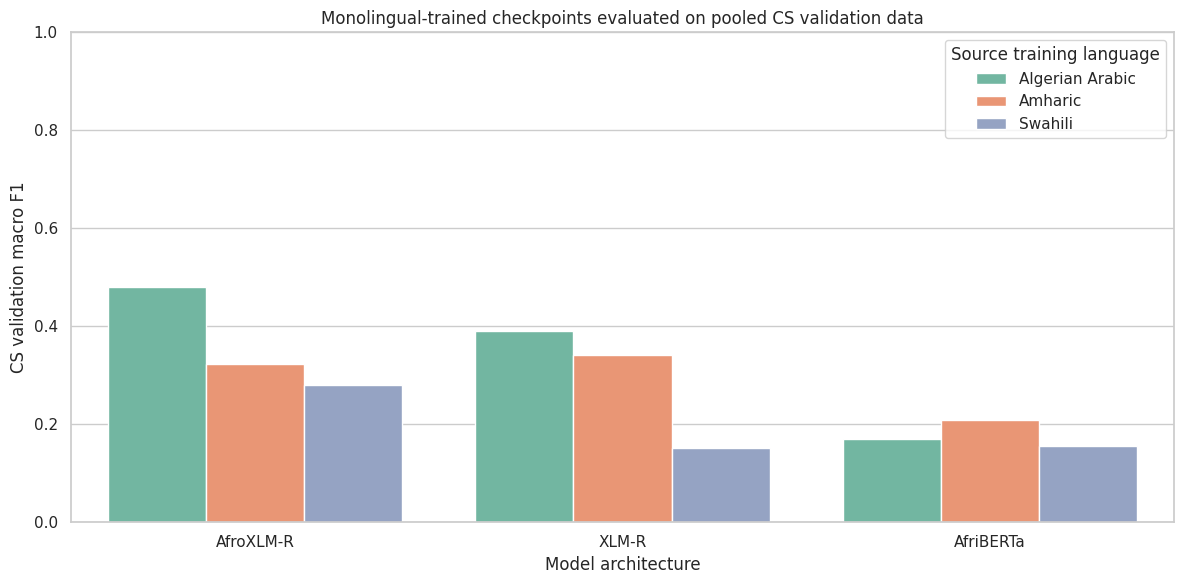

In [65]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=successful_validation_results,
    x="model",
    y="macro_f1",
    hue="source_language",
    palette="Set2",
)

plt.title(
    "Monolingual-trained checkpoints evaluated "
    "on pooled CS validation data"
)

plt.xlabel("Model architecture")
plt.ylabel("CS validation macro F1")
plt.ylim(0, 1)
plt.legend(title="Source training language")
plt.tight_layout()
plt.show()

In [66]:
if successful_validation_results.empty:
    raise ValueError(
        "No monolingual checkpoint was evaluated successfully."
    )

best_checkpoint_row = (
    successful_validation_results.iloc[0]
)

best_source_language = best_checkpoint_row[
    "source_language"
]

best_model_name = best_checkpoint_row["model"]

best_mono_checkpoint = best_checkpoint_row[
    "checkpoint"
]

best_model_base_checkpoint = MODEL_CONFIG[
    best_model_name
]

print("Best monolingual-trained checkpoint")
print("-----------------------------------")
print("Source language:", best_source_language)
print("Architecture:", best_model_name)
print("Saved checkpoint:", best_mono_checkpoint)
print(
    "CS validation macro F1:",
    round(
        best_checkpoint_row["macro_f1"],
        4,
    ),
)

Best monolingual-trained checkpoint
-----------------------------------
Source language: Algerian Arabic
Architecture: AfroXLM-R
Saved checkpoint: /content/afrisenti_monolingual_results/models/algerian_arabic_afroxlm_r/best_model
CS validation macro F1: 0.4796


In [67]:
cs_test_results = []
cs_test_per_language = []
cs_test_predictions = []

for _, checkpoint_row in (
    mono_checkpoint_table.iterrows()
):
    source_language = checkpoint_row["language"]
    model_name = checkpoint_row["model"]
    checkpoint_path = checkpoint_row[
        "saved_checkpoint"
    ]

    try:
        (
            overall_result,
            language_results,
            prediction_results,
        ) = evaluate_mono_checkpoint_on_cs(
            checkpoint_path=checkpoint_path,
            evaluation_df=cs_test_df,
            source_language=source_language,
            model_name=model_name,
            split_name="cs_test",
        )

        cs_test_results.append(
            overall_result
        )

        cs_test_per_language.append(
            language_results
        )

        cs_test_predictions.append(
            prediction_results
        )

    except Exception as error:
        print("\n" + "!" * 100)
        print(
            "Test evaluation failed:",
            source_language,
            "|",
            model_name,
        )
        print(type(error).__name__, ":", error)
        print("!" * 100)

        cs_test_results.append({
            "source_language": source_language,
            "model": model_name,
            "checkpoint": checkpoint_path,
            "evaluation_split": "cs_test",
            "error": str(error),
        })


Source monolingual language: Algerian Arabic
Model: AfroXLM-R
Target split: cs_test
Checkpoint: /content/afrisenti_monolingual_results/models/algerian_arabic_afroxlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizing cs_test for Algerian Arabic AfroXLM-R:   0%|          | 0/7438 [00:00<?, ? examples/s]


Evaluation arguments being used:
  output_dir: /content/afrisenti_monolingual_results/mono_to_cs_evaluation/temporary
  per_device_eval_batch_size: 32
  seed: 42
  data_seed: 42
  report_to: none
  run_name: algerian_arabic_afroxlm_r_cs_test
  eval_strategy: no
  save_strategy: no
  fp16: True
  dataloader_num_workers: 2



Source monolingual language: Algerian Arabic
Model: XLM-R
Target split: cs_test
Checkpoint: /content/afrisenti_monolingual_results/models/algerian_arabic_xlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

... (26 outputs left out)


Source monolingual language: Swahili
Model: XLM-R
Target split: cs_test
Checkpoint: /content/afrisenti_monolingual_results/models/swahili_xlm_r/best_model


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Tokenizing cs_test for Swahili XLM-R:   0%|          | 0/7438 [00:00<?, ? examples/s]


Evaluation arguments being used:
  output_dir: /content/afrisenti_monolingual_results/mono_to_cs_evaluation/temporary
  per_device_eval_batch_size: 32
  seed: 42
  data_seed: 42
  report_to: none
  run_name: swahili_xlm_r_cs_test
  eval_strategy: no
  save_strategy: no
  fp16: True
  dataloader_num_workers: 2


In [68]:
cs_test_results_df = pd.DataFrame(
    cs_test_results
)

cs_test_per_language_df = pd.concat(
    cs_test_per_language,
    ignore_index=True,
)

cs_test_predictions_df = pd.concat(
    cs_test_predictions,
    ignore_index=True,
)

successful_test_results = (
    cs_test_results_df[
        cs_test_results_df["macro_f1"].notna()
    ]
    .sort_values(
        "macro_f1",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    successful_test_results[
        [
            "source_language",
            "model",
            "accuracy",
            "macro_precision",
            "macro_recall",
            "macro_f1",
            "weighted_f1",
            "negative_f1",
            "neutral_f1",
            "positive_f1",
        ]
    ].round(4)
)

,source_language,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Algerian Arabic,AfroXLM-R,0.4324,0.4601,0.4226,0.4082,0.4132,0.5165,0.3862,0.3220
1,Amharic,AfroXLM-R,0.3894,0.5683,0.4163,0.3471,0.3414,0.3394,0.4702,0.2317
2,Amharic,XLM-R,0.3889,0.5954,0.4198,0.3350,0.3276,0.3089,0.4837,0.2126
3,Algerian Arabic,XLM-R,0.3860,0.4309,0.3627,0.3045,0.3149,0.5235,0.2533,0.1369
4,Amharic,AfriBERTa,0.3424,0.5546,0.3764,0.2707,0.2594,0.1840,0.4558,0.1723
5,Swahili,AfroXLM-R,0.3482,0.6940,0.3842,0.2542,0.2435,0.2228,0.4720,0.0679
6,Algerian Arabic,AfriBERTa,0.2739,0.1726,0.3064,0.1760,0.1629,0.1092,0.4189,0.0000
7,Swahili,AfriBERTa,0.3017,0.6265,0.3430,0.1724,0.1537,0.0014,0.4545,0.0612
8,Swahili,XLM-R,0.2944,0.3668,0.3360,0.1565,0.1377,0.0000,0.4527,0.0167


In [69]:
display(
    cs_test_per_language_df[
        [
            "source_language",
            "model",
            "target_language",
            "evaluation_size",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
    .sort_values(
        [
            "source_language",
            "model",
            "target_language",
        ]
    )
    .round(4)
)

,source_language,model,target_language,evaluation_size,accuracy,macro_f1,weighted_f1
6,Algerian Arabic,AfriBERTa,Igbo,3682,0.3935,0.2472,0.2945
7,Algerian Arabic,AfriBERTa,Nigerian Pidgin,3026,0.1547,0.1029,0.0665
8,Algerian Arabic,AfriBERTa,Twi,730,0.1644,0.1015,0.0541
0,Algerian Arabic,AfroXLM-R,Igbo,3682,0.3620,0.3571,0.3686
1,Algerian Arabic,AfroXLM-R,Nigerian Pidgin,3026,0.5473,0.4425,0.5106
2,Algerian Arabic,AfroXLM-R,Twi,730,0.3110,0.3068,0.3012
3,Algerian Arabic,XLM-R,Igbo,3682,0.2781,0.2427,0.2418
4,Algerian Arabic,XLM-R,Nigerian Pidgin,3026,0.5198,0.3305,0.4223
5,Algerian Arabic,XLM-R,Twi,730,0.3753,0.3269,0.3245
9,Amharic,AfriBERTa,Igbo,3682,0.5027,0.3960,0.4343


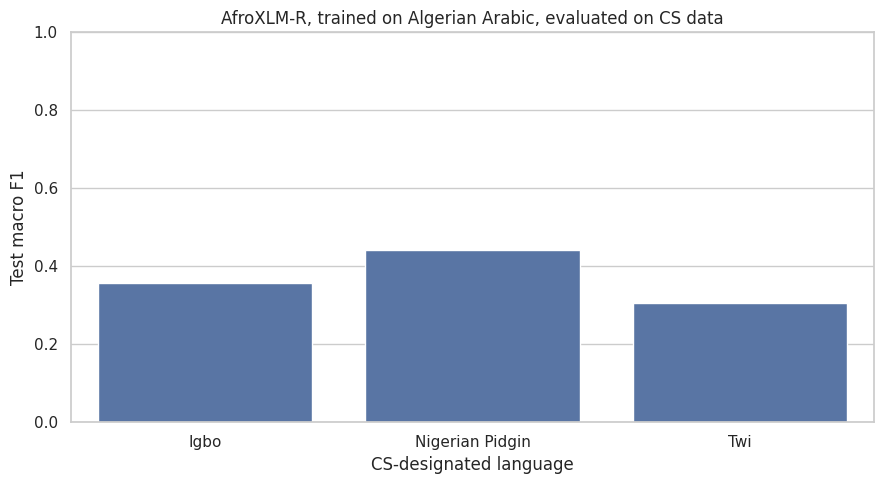

In [70]:
best_baseline_language_results = (
    cs_test_per_language_df[
        (
            cs_test_per_language_df[
                "source_language"
            ] == best_source_language
        )
        &
        (
            cs_test_per_language_df["model"]
            == best_model_name
        )
    ]
    .copy()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=best_baseline_language_results,
    x="target_language",
    y="macro_f1",
    color="#4C72B0",
)

plt.title(
    f"{best_model_name}, trained on "
    f"{best_source_language}, evaluated on CS data"
)

plt.xlabel("CS-designated language")
plt.ylabel("Test macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Amharic train
+ Algerian Arabic train
+ Swahili train
+ Igbo train
+ Nigerian Pidgin train
+ Twi train

In [71]:
mono_train_df = pool_language_split(
    cleaned_language_frames=cleaned_frames,
    language_names=MONO_LANGUAGE_NAMES,
    split_name="train",
    dataset_group="Mono",
)

In [72]:
cs_train_df = pool_language_split(
    cleaned_language_frames=cs_cleaned_frames,
    language_names=CS_LANGUAGE_NAMES,
    split_name="train",
    dataset_group="CS",
)

In [73]:
augmented_train_df = pd.concat(
    [
        mono_train_df,
        cs_train_df,
    ],
    ignore_index=True,
)

augmented_train_df = augmented_train_df.sample(
    frac=1,
    random_state=SEED,
).reset_index(drop=True)

print("Mono training size:", len(mono_train_df))
print("CS training size:", len(cs_train_df))
print(
    "Total augmented training size:",
    len(augmented_train_df),
)

Mono training size: 9428
CS training size: 18025
Total augmented training size: 27453


In [74]:
display(
    augmented_train_df[
        "dataset_group"
    ].value_counts().to_frame("count")
)

display(
    pd.crosstab(
        augmented_train_df["language"],
        augmented_train_df["label_name"],
        margins=True,
    )
)

,count
dataset_group,
CS,18025
Mono,9428


label_name,negative,neutral,positive,All
language,,,,
Algerian Arabic,885,342,414,1641
Amharic,1547,3104,1331,5982
Igbo,2600,4508,3084,10192
Nigerian Pidgin,3003,70,1568,4641
Swahili,191,1070,544,1805
Twi,1184,510,1498,3192
All,9410,9604,8439,27453


Train:       Mono train + CS train
Validation:  CS validation
Test:        CS test

In [75]:
augmented_hf_dataset = DatasetDict({
    "train": classification_frame_to_dataset(
        augmented_train_df
    ),

    "validation": classification_frame_to_dataset(
        cs_validation_df
    ),

    "test": classification_frame_to_dataset(
        cs_test_df
    ),
})

print(augmented_hf_dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 27453
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 3111
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7438
    })
})


Mono-only training data
versus
Mono + CS training data

In [77]:
def train_and_evaluate_cs_model(
    model_name,
    model_checkpoint,
    dataset_dict,
    metadata_test_df,
    experiment_group,
):
    import os
    import gc
    import torch
    import numpy as np
    import pandas as pd
    from transformers import AutoTokenizer, AutoConfig, AutoModelForSequenceClassification, Trainer, DataCollatorWithPadding

    print(f"Training CS model: {model_name} on {experiment_group}...")

    # 1. Tokenizer
    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, use_fast=False)
    tokenizer.model_max_length = MAX_LENGTH

    # 2. Tokenize
    def tokenize_batch(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
            padding=False,
        )

    tokenized_dataset = dataset_dict.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"],
    )
    tokenized_dataset = tokenized_dataset.rename_column("label", "labels")
    tokenized_dataset.set_format("torch")

    data_collator = DataCollatorWithPadding(
        tokenizer=tokenizer,
        pad_to_multiple_of=8 if torch.cuda.is_available() else None,
    )

    # 3. Model Configuration
    config = AutoConfig.from_pretrained(
        model_checkpoint,
        num_labels=NUM_LABELS,
        label2id=LABEL2ID,
        id2label=ID2LABEL,
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        model_checkpoint,
        config=config,
        ignore_mismatched_sizes=True,
    )

    # 4. Training Arguments
    output_dir = os.path.join(OUTPUT_ROOT, "models", experiment_group)
    training_args = create_training_arguments(
        output_dir=output_dir,
        run_name=experiment_group,
    )

    # 5. Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_dataset["train"],
        eval_dataset=tokenized_dataset["validation"],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    # 6. Train
    trainer.train()

    # 7. Evaluate on Test
    predictions = trainer.predict(tokenized_dataset["test"])
    test_metrics = predictions.metrics
    test_logits = predictions.predictions
    predicted_labels = np.argmax(test_logits, axis=-1)

    # Convert predictions to overall result
    result = {
        "experiment": experiment_group,
        "architecture": model_name,
        "accuracy": test_metrics.get("test_accuracy"),
        "macro_precision": test_metrics.get("test_macro_precision"),
        "macro_recall": test_metrics.get("test_macro_recall"),
        "macro_f1": test_metrics.get("test_macro_f1"),
        "weighted_f1": test_metrics.get("test_weighted_f1"),
        "negative_f1": test_metrics.get("test_negative_f1"),
        "neutral_f1": test_metrics.get("test_neutral_f1"),
        "positive_f1": test_metrics.get("test_positive_f1"),
    }

    # Evaluate metrics per language split on test metadata
    predictions_df = metadata_test_df.copy().reset_index(drop=True)
    predictions_df["predicted_label_id"] = predicted_labels
    predictions_df["true_label_id"] = predictions_df["label"].astype(int)

    per_language_results = []
    for target_language in sorted(predictions_df["language"].unique()):
        subset = predictions_df[predictions_df["language"] == target_language]
        subset_true = subset["true_label_id"].to_numpy()
        subset_predicted = subset["predicted_label_id"].to_numpy()

        (prec, rec, f1, _) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="macro",
            zero_division=0,
        )
        (_, _, wf1, _) = precision_recall_fscore_support(
            subset_true,
            subset_predicted,
            average="weighted",
            zero_division=0,
        )
        per_language_results.append({
            "language": target_language,
            "accuracy": accuracy_score(subset_true, subset_predicted),
            "macro_f1": f1,
            "weighted_f1": wf1,
        })

    per_language_df = pd.DataFrame(per_language_results)

    # Cleanup
    del trainer
    del model
    del tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, per_language_df


augmented_result, augmented_per_language = (
    train_and_evaluate_cs_model(
        model_name=best_model_name,
        model_checkpoint=best_model_base_checkpoint,
        dataset_dict=augmented_hf_dataset,
        metadata_test_df=cs_test_df,
        experiment_group="mono_plus_cs_augmented",
    )
)

Training CS model: AfroXLM-R on mono_plus_cs_augmented...


Map:   0%|          | 0/27453 [00:00<?, ? examples/s]

Map:   0%|          | 0/3111 [00:00<?, ? examples/s]

Map:   0%|          | 0/7438 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [79]:
selected_mono_test_result = (
    successful_test_results[
        (
            successful_test_results[
                "source_language"
            ] == best_source_language
        )
        &
        (
            successful_test_results["model"]
            == best_model_name
        )
    ]
    .iloc[0]
)

In [80]:
augmentation_comparison = pd.DataFrame([
    {
        "experiment": "Monolingual-trained model",
        "architecture": best_model_name,
        "source_training_language": (
            best_source_language
        ),
        "training_data": (
            f"{best_source_language} train only"
        ),
        "accuracy": selected_mono_test_result[
            "accuracy"
        ],
        "macro_f1": selected_mono_test_result[
            "macro_f1"
        ],
        "weighted_f1": selected_mono_test_result[
            "weighted_f1"
        ],
        "negative_f1": selected_mono_test_result[
            "negative_f1"
        ],
        "neutral_f1": selected_mono_test_result[
            "neutral_f1"
        ],
        "positive_f1": selected_mono_test_result[
            "positive_f1"
        ],
    },
    {
        "experiment": "Augmented model",
        "architecture": best_model_name,
        "source_training_language": "Multilingual",
        "training_data": "Mono train + CS train",
        "accuracy": augmented_result[
            "accuracy"
        ],
        "macro_f1": augmented_result[
            "macro_f1"
        ],
        "weighted_f1": augmented_result[
            "weighted_f1"
        ],
        "negative_f1": augmented_result[
            "negative_f1"
        ],
        "neutral_f1": augmented_result[
            "neutral_f1"
        ],
        "positive_f1": augmented_result[
            "positive_f1"
        ],
    },
])

display(augmentation_comparison.round(4))

,experiment,architecture,source_training_language,training_data,accuracy,macro_f1,weighted_f1,negative_f1,neutral_f1,positive_f1
0,Monolingual-trained model,AfroXLM-R,Algerian Arabic,Algerian Arabic train only,0.4324,0.4082,0.4132,0.5165,0.3862,0.3220
1,Augmented model,AfroXLM-R,Multilingual,Mono train + CS train,0.6997,0.6941,0.6973,0.7242,0.6468,0.7112


In [81]:
baseline_macro_f1 = (
    augmentation_comparison.loc[
        augmentation_comparison["experiment"]
        == "Monolingual-trained model",
        "macro_f1",
    ].iloc[0]
)

augmented_macro_f1 = (
    augmentation_comparison.loc[
        augmentation_comparison["experiment"]
        == "Augmented model",
        "macro_f1",
    ].iloc[0]
)

absolute_change = (
    augmented_macro_f1
    - baseline_macro_f1
)

if baseline_macro_f1 > 0:
    relative_change_percentage = (
        absolute_change
        / baseline_macro_f1
        * 100
    )
else:
    relative_change_percentage = np.nan

print(
    f"Monolingual baseline macro F1: "
    f"{baseline_macro_f1:.4f}"
)

print(
    f"Augmented model macro F1: "
    f"{augmented_macro_f1:.4f}"
)

print(
    f"Absolute change: "
    f"{absolute_change:+.4f}"
)

print(
    f"Relative change: "
    f"{relative_change_percentage:+.2f}%"
)

Monolingual baseline macro F1: 0.4082
Augmented model macro F1: 0.6941
Absolute change: +0.2859
Relative change: +70.02%


In [82]:
baseline_by_language = (
    cs_test_per_language_df[
        (
            cs_test_per_language_df[
                "source_language"
            ] == best_source_language
        )
        &
        (
            cs_test_per_language_df["model"]
            == best_model_name
        )
    ]
    .copy()
)

baseline_by_language = (
    baseline_by_language.rename(
        columns={
            "target_language": "language"
        }
    )
)

baseline_by_language["experiment"] = (
    "Monolingual-trained model"
)

In [83]:
augmented_by_language = (
    augmented_per_language.copy()
)

augmented_by_language["experiment"] = (
    "Augmented model"
)

In [84]:
language_augmentation_comparison = pd.concat(
    [
        baseline_by_language[
            [
                "language",
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "experiment",
            ]
        ],
        augmented_by_language[
            [
                "language",
                "accuracy",
                "macro_f1",
                "weighted_f1",
                "experiment",
            ]
        ],
    ],
    ignore_index=True,
)

display(
    language_augmentation_comparison
    .sort_values(
        ["language", "experiment"]
    )
    .round(4)
)

,language,accuracy,macro_f1,weighted_f1,experiment
3,Igbo,0.7471,0.7402,0.7451,Augmented model
0,Igbo,0.3620,0.3571,0.3686,Monolingual-trained model
4,Nigerian Pidgin,0.6609,0.4686,0.6082,Augmented model
1,Nigerian Pidgin,0.5473,0.4425,0.5106,Monolingual-trained model
5,Twi,0.6205,0.5040,0.5928,Augmented model
2,Twi,0.3110,0.3068,0.3012,Monolingual-trained model


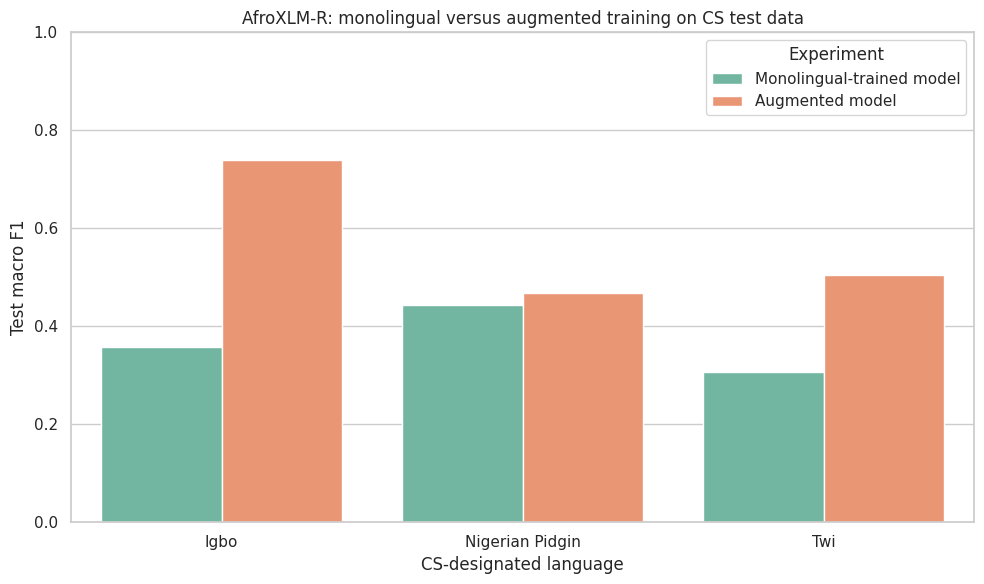

In [85]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=language_augmentation_comparison,
    x="language",
    y="macro_f1",
    hue="experiment",
    palette="Set2",
)

plt.title(
    f"{best_model_name}: monolingual versus "
    "augmented training on CS test data"
)

plt.xlabel("CS-designated language")
plt.ylabel("Test macro F1")
plt.ylim(0, 1)
plt.legend(title="Experiment")
plt.tight_layout()
plt.show()

In [86]:
language_change = (
    language_augmentation_comparison.pivot(
        index="language",
        columns="experiment",
        values="macro_f1",
    )
    .reset_index()
)

language_change["absolute_change"] = (
    language_change["Augmented model"]
    - language_change[
        "Monolingual-trained model"
    ]
)

language_change["relative_change_percent"] = (
    language_change["absolute_change"]
    / language_change[
        "Monolingual-trained model"
    ]
    * 100
)

display(language_change.round(4))

experiment,language,Augmented model,Monolingual-trained model,absolute_change,relative_change_percent
0,Igbo,0.7402,0.3571,0.3831,107.2889
1,Nigerian Pidgin,0.4686,0.4425,0.0261,5.8931
2,Twi,0.5040,0.3068,0.1972,64.2859


In [87]:
FINAL_RESULTS_PATH = os.path.join(
    MONO_TO_CS_OUTPUT,
    "mono_to_cs_and_augmentation_results.xlsx",
)

with pd.ExcelWriter(
    FINAL_RESULTS_PATH,
    engine="openpyxl",
) as writer:

    successful_validation_results.to_excel(
        writer,
        sheet_name="CS validation ranking",
        index=False,
    )

    successful_test_results.to_excel(
        writer,
        sheet_name="CS test results",
        index=False,
    )

    cs_test_per_language_df.to_excel(
        writer,
        sheet_name="CS test by language",
        index=False,
    )

    augmentation_comparison.to_excel(
        writer,
        sheet_name="Augmentation overall",
        index=False,
    )

    language_augmentation_comparison.to_excel(
        writer,
        sheet_name="Augmentation by language",
        index=False,
    )

    language_change.to_excel(
        writer,
        sheet_name="Language change",
        index=False,
    )

print("Saved:", FINAL_RESULTS_PATH)

Saved: /content/afrisenti_monolingual_results/mono_to_cs_evaluation/mono_to_cs_and_augmentation_results.xlsx
